# comparing_model8 — GM12878 expression specificity and amplitude

**Question:** does the GM12878-specialized cis-Mamba model predict promoter-expression
deviations as accurately as Enformer, and does EpiBERT recover deviations in its own RAMPAGE task?

Two separate experiments, as requested:

1. **Enformer CAGE:** cis-Mamba (`GM12878_no_mlm`) versus released Enformer (track 5110),
   with identical measured CAGE targets and held-out promoters.
2. **RAMPAGE:** EpiBERT alone versus measured-reference controls, on its native transformed target.
   No CAGE-to-RAMPAGE model comparison and no cross-assay ranking of the metrics.

The saved `comparing_model7.ipynb` and original proposal are unchanged. Read the executed
tables and closing interpretation below; input caches and saved figures are in `comparing_model8_results/`.
`prepare_model8.py` builds the input caches; all metric and plotting code is in this notebook.

## What the proposal gets right, and what needs changing

Correlation can hide severe amplitude compression. Adding slope, spread, signed error, and
specificity strata is useful. However, this is an **exploratory specificity benchmark**, not
by itself evidence that multitask learning causes regression toward a biological mean.

- **Use the same centering for every model.** Own-predicted-mean centering for Enformer and
  observed-mean centering for cis-Mamba estimate different quantities. Here both subtract
  the same measured, leave-GM12878-out reference. This is a reference-assisted diagnostic,
  not autonomous prediction of a cross-cell expression contrast.
- **Shared-reference correlation can be misleading.** Both axes contain the same `−mean`.
  Even a predictor that outputs zero expression can correlate after subtraction. We include
  that control, ordinary expression correlation, and improvement over predicting the reference mean.
- **Slope is not sufficient.** With an intercept, `slope = Pearson r × SD ratio`. A low slope can
  reflect noise/decorrelation, not only compressed amplitude. Observed expression has measurement
  error, so regression on observed deviations also suffers errors-in-variables attenuation.
  Correctly shrinking uncertain predictions can minimize error. Inspect all metrics together.
- **Deviation error is not new under common centering:**
  `(prediction − mean) − (observation − mean) = prediction − observation`.
  Thus MAE/RMSE equal ordinary expression error; their specificity dependence is informative.
- **Panel and transform matter.** Mean of log signals differs from log of their arithmetic mean.
  Repeated tissues/donors receive repeated weight here. These are other-*dataset* references,
  not equally weighted, independent cell types. Low panel average does not imply exclusive expression.
- **Strong observed tails are noisy selections.** The nested top-|d| strata are descriptive;
  selection on measurement noise can itself exaggerate apparent shrinkage. Independent replicates
  are needed for noise-corrected claims and reproducible tail selection.
- **Scope:** one GM12878-specialized model versus a multitask model changes training,
  architecture, capacity, context, and **input modalities**. The historical exporter associates
  `GM12878_no_mlm` with a model receiving measured GM12878 DNase and sequence; Enformer
  is sequence-only. Enformer *does* have cell-specific output heads. Call it multitask,
  not non-cell-specific. The associated cis-Mamba configuration has a CAGE-only fine-tuning
  loss; that does not mean sequence-only inputs or expression-only pretraining. These assays report transcription
  initiation at promoters, not whole-gene RNA abundance or allelic/perturbation effects.

## Data and readout fixed before scoring

Use the 1,840 sequence-verified regions from notebook 7, exclude the three shifted edge grids,
and remove identical genomic windows. Independently recheck the EpiBERT 524-kb input/training
overlap filter and notebook 7's CAGE overlap filter. This uses a conservative common subset;
it is not a census of every original Enformer test region or a complete checkpoint split audit.

GENCODE v49 protein-coding genes: choose the longest genomic-span transcript per gene,
breaking ties by transcript ID **without expression or predictions**. Its TSS is `start0`
on `+` and `end0−1` on `−`. Require the widest ±1,024-bp window to fit within an output region;
choose the most central region if several cover the same gene. The primary readout sums the
eight 128-bp bins with centers in TSS ±512 bp. Both narrower and wider windows use the same genes.
This is an unstranded, representative-promoter expression proxy; it can miss alternative promoters
and mix nearby genes. A sensitivity analysis excludes promoters overlapping another selected gene.

CAGE uses released Enformer target units and the two saved predictions, with an exact check
that cis-Mamba targets and Zarr track 5110 agree. RAMPAGE uses **clip(raw, 0, 65500), square root,
then Gaussian smoothing (width 3, SD 1 bin), before cropping**, exactly as in EpiBERT's local
training code. Every record in all 50 TFRecord files is matched by full-sequence SHA256;
raw GM12878 promoter sums also reproduce notebook 7's aligned cache. Squaring a smoothed
prediction is not an inverse of this transform. No raw-RAMPAGE amplitude claim is made.

For promoter sum `s`, let `y = log2(s + 1)`, and let `mu` be the mean of `y` across the
**637 other CAGE tracks** or **49 other RAMPAGE datasets**. Use `d = y_GM12878 − mu` and
`d_hat = y_hat_GM12878 − mu`. The native RAMPAGE log units refer to transformed signal,
not raw expression fold changes. No z-scoring, quantile normalization, or test-fitted calibration.

Uncertainty: 1,000 paired bootstrap draws of connected components of overlapping 524-kb
model inputs. All genes in a component are resampled together; the same draws serve every
model. Intervals are conditional on the observed panel, gene set, and fixed stratum membership;
they do not include training-seed or experimental-replicate variability.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from IPython.display import display, Markdown

# Input caches are built by prepare_model8.py (see the reproduction notes below).
HERE = Path('/data1/lesliec/sarthak/caduceus/notebooks/model_eval/cage_rna')
OUT = HERE / 'comparing_model8_results'
COLORS = {'cis-Mamba':'#177A3B','Enformer':'#A32316','EpiBERT':'#0F8C8C',
          'Other-track mean':'#6B7280','Zero expression control':'#BBBBBB'}
N_BOOT = 1000
SEED = 20260925


def load_inputs():
    promoters = pd.read_csv(OUT/'promoters.tsv',sep='\t')
    cage, rp = np.load(OUT/'cage_promoter_inputs.npz'), np.load(OUT/'rampage_promoter_inputs.npz')
    assert len(promoters) == len(cage['measured']) == len(rp['measured_native'])
    assert promoters.groupby('pad').gene_id.nunique().nunique() == 1
    return promoters, {
        'CAGE':dict(measured=cage['measured'],gm=5110-4675,
                    predictions={name:cage[name] for name in ['cis-Mamba','Enformer']}),
        'RAMPAGE native':dict(measured=rp['measured_native'],gm=int(rp['gm_index']),
                              predictions={'EpiBERT':rp['epibert']})}


def make_frame(promoters, data, pad=512, pseudocount=1., baseline='mean_log'):
    keep = promoters['pad'].to_numpy() == pad
    frame = promoters.loc[keep].reset_index(drop=True).copy()
    raw = data['measured'][keep]
    logs = np.log2(raw+pseudocount)
    other = np.arange(raw.shape[1]) != data['gm']
    y = logs[:,data['gm']]
    mu = (logs[:,other].mean(axis=1) if baseline == 'mean_log'
          else np.log2(raw[:,other].mean(axis=1)+pseudocount))
    frame['observed'] = y
    frame['reference_mean'] = mu
    frame['d_obs'] = y-mu
    frame['raw_observed'] = raw[:,data['gm']]
    for name,pred in data['predictions'].items():
        yp = np.log2(pred[keep]+pseudocount)
        frame[name] = yp-mu
        assert np.allclose((yp-mu)-(y-mu),yp-y)
    frame['Other-track mean'] = 0.
    frame['Zero expression control'] = np.log2(pseudocount)-mu
    return frame


def corr(x,y):
    if len(x)<3 or np.std(x)<1e-12 or np.std(y)<1e-12:
        return np.nan
    return np.corrcoef(x,y)[0,1]


def metrics(x,y):
    x,y = np.asarray(x,float),np.asarray(y,float)
    assert np.isfinite(x).all() and np.isfinite(y).all()
    if len(x)<3:
        return {k:np.nan for k in ['pearson','spearman','slope','intercept','sd_ratio','mae',
                                    'rmse','bias','skill_vs_mean','concordance','sign_accuracy']}
    vx,vy = np.var(x),np.var(y)
    cov = np.mean((x-x.mean())*(y-y.mean()))
    slope = cov/vx if vx>1e-15 else np.nan
    error = y-x
    mse = np.mean(error**2)
    null = np.mean(x*x)
    denominator = vx+vy+(x.mean()-y.mean())**2
    nonzero = np.abs(x)>1e-12
    return dict(pearson=corr(x,y),spearman=corr(rankdata(x),rankdata(y)),slope=slope,
                intercept=y.mean()-slope*x.mean(),sd_ratio=np.sqrt(vy/vx) if vx>1e-15 else np.nan,
                mae=np.mean(np.abs(error)),rmse=np.sqrt(mse),bias=error.mean(),
                skill_vs_mean=1-mse/null if null>1e-15 else np.nan,
                concordance=2*cov/denominator if denominator>1e-15 else np.nan,
                sign_accuracy=np.mean(np.sign(x[nonzero])==np.sign(y[nonzero])) if nonzero.any() else np.nan)


def strata(frame):
    x = frame.d_obs.to_numpy()
    result = {'All':np.ones(len(x),bool)}
    for fraction in [.5,.2,.1,.05]:
        threshold = np.quantile(np.abs(x),1-fraction)
        result[f'Top {fraction:.0%} |d|'] = np.abs(x)>=threshold
    result['Positive d'] = x>0
    result['Negative d'] = x<0
    result['d >= 1'] = x>=1
    result['d <= -1'] = x<=-1
    return result


def bootstrap(frame, model, mask, n_boot=N_BOOT):
    """Paired connected-context block draws; strata membership fixed before resampling.

    Block sufficient statistics avoid creating 1000 expanded gene tables.
    Identical seed and block universe give identical draws for all arms/strata.
    """
    blocks,block_ids = np.unique(frame.block,return_inverse=True)
    nb = len(blocks)
    rng = np.random.default_rng(SEED)
    weights = rng.multinomial(nb,np.repeat(1/nb,nb),size=n_boot)
    x,y = frame.d_obs.to_numpy()[mask],frame[model].to_numpy()[mask]
    b = block_ids[mask]
    values = [np.ones(len(x)),x,y,x*x,y*y,x*y,(y-x)**2,np.abs(y-x)]
    totals = np.column_stack([np.bincount(b,weights=v,minlength=nb) for v in values])
    draws = weights@totals
    n = draws[:,0]
    with np.errstate(divide='ignore',invalid='ignore'):
        mx,my,xx,yy,xy,mse,mae = (draws[:,i]/n for i in range(1,8))
        vx,vy,cov = np.maximum(xx-mx*mx,0),np.maximum(yy-my*my,0),xy-mx*my
        slope = np.where(vx>1e-15,cov/vx,np.nan)
        result = dict(pearson=np.where(vx*vy>1e-24,cov/np.sqrt(vx*vy),np.nan),
            slope=slope,intercept=my-slope*mx,sd_ratio=np.sqrt(vy/vx),
            rmse=np.sqrt(mse),mae=mae,bias=my-mx,skill_vs_mean=1-mse/xx,
            concordance=2*cov/(vx+vy+(mx-my)**2))
    for k,v in result.items():
        result[k] = np.where(n>=3,v,np.nan)
    return result


def evaluate(frame, assay, models, n_boot=N_BOOT):
    rows,draws = [],{}
    for subset,mask in strata(frame).items():
        for model in models:
            x,y = frame.loc[mask,'d_obs'].to_numpy(),frame.loc[mask,model].to_numpy()
            row = dict(assay=assay,subset=subset,model=model,n_genes=int(mask.sum()),
                       n_blocks=frame.loc[mask,'block'].nunique(),**metrics(x,y))
            row['expression_pearson'] = corr(frame.loc[mask,'observed'],
                                             frame.loc[mask,model]+frame.loc[mask,'reference_mean'])
            if n_boot:
                draws[subset,model] = boot = bootstrap(frame,model,mask,n_boot)
                for metric,v in boot.items():
                    finite = np.isfinite(v)
                    row[f'{metric}_valid_draws'] = int(finite.sum())
                    ci = np.quantile(v[finite],[.025,.975]) if finite.sum()>=n_boot*.9 else [np.nan,np.nan]
                    row[f'{metric}_lo'],row[f'{metric}_hi'] = ci
            rows.append(row)
    return pd.DataFrame(rows),draws


def paired_differences(table,draws):
    rows = []
    for subset in table.subset.unique():
        group = table[table.subset==subset].set_index('model')
        for metric in ['pearson','rmse','mae','skill_vs_mean','slope','sd_ratio']:
            a,b = draws[subset,'cis-Mamba'][metric],draws[subset,'Enformer'][metric]
            delta = a-b
            finite = np.isfinite(delta)
            lo,hi = np.quantile(delta[finite],[.025,.975]) if finite.sum()>=len(a)*.9 else (np.nan,np.nan)
            rows.append(dict(subset=subset,metric=metric,
                difference=group.loc['cis-Mamba',metric]-group.loc['Enformer',metric],
                lo=lo,hi=hi,valid_draws=int(finite.sum()),
                direction='lower is better' if metric in ['rmse','mae'] else
                          ('closer to 1 is better; signed difference is not superiority' if metric in ['slope','sd_ratio'] else 'higher is better')))
    return pd.DataFrame(rows)


def scatter_figure(frame, assay, models):
    fig,axes = plt.subplots(1,len(models),figsize=(5*len(models),4.5),squeeze=False)
    all_values = np.concatenate([frame.d_obs.to_numpy()]+[frame[m].to_numpy() for m in models])
    lim = [all_values.min()-.2,all_values.max()+.2]
    for ax,model in zip(axes[0],models):
        x,y = frame.d_obs.to_numpy(),frame[model].to_numpy()
        m = metrics(x,y)
        ax.hexbin(x,y,gridsize=40,mincnt=1,bins='log',cmap='Greys',linewidths=0)
        ax.plot(lim,lim,'k--',lw=1,label='Identity')
        ax.plot(lim,m['intercept']+m['slope']*np.array(lim),color=COLORS[model],lw=2,label='OLS predicted on observed')
        # Equal-population means expose sign asymmetry without fitting a calibration map.
        groups = np.array_split(np.argsort(x),10)
        ax.plot([x[g].mean() for g in groups],[y[g].mean() for g in groups],'o-',
                color=COLORS[model],ms=4,label='Decile means')
        ax.axhline(0,color='.8',lw=.6);ax.axvline(0,color='.8',lw=.6)
        ax.set(xlabel='Observed deviation',ylabel='Predicted deviation',xlim=lim,ylim=lim,
               title=f"{model}\nr={m['pearson']:.3f}, slope={m['slope']:.3f}, SD={m['sd_ratio']:.3f}")
        ax.legend(fontsize=7)
    fig.suptitle(f'{assay}: log2 promoter signal relative to measured other-track mean',fontsize=11)
    fig.tight_layout()
    return fig


def specificity_figure(table, assay, models):
    subsets = ['All','Top 50% |d|','Top 20% |d|','Top 10% |d|','Top 5% |d|']
    fig,axes = plt.subplots(1,4,figsize=(16,3.8))
    for ax,metric,label,ideal in zip(axes,['pearson','slope','sd_ratio','rmse'],
                                   ['Pearson r','Attenuation slope','SD ratio','RMSE'],[None,1,1,None]):
        for model in models:
            t = table[(table.model==model)&table.subset.isin(subsets)].set_index('subset').loc[subsets]
            y = t[metric].to_numpy()
            ax.plot(range(5),y,'o-',label=model,color=COLORS[model])
            ax.fill_between(range(5),t[f'{metric}_lo'],t[f'{metric}_hi'],color=COLORS[model],alpha=.12)
        if ideal is not None: ax.axhline(ideal,color='k',ls='--',lw=1)
        ax.set(xticks=range(5),xticklabels=['All','50%','20%','10%','5%'],ylabel=label,
               xlabel='Largest observed |deviation|')
    axes[0].legend(fontsize=8)
    fig.suptitle(f'{assay}: specificity strata (paired block-bootstrap 95% intervals)')
    fig.tight_layout()
    return fig


def diagnostic_figure(frames):
    fig,axes = plt.subplots(1,2,figsize=(12,4))
    for ax,(assay,frame) in zip(axes,frames.items()):
        names = ['cis-Mamba','Enformer'] if assay == 'CAGE' else ['EpiBERT']
        for model in names:
            x = frame.d_obs.to_numpy()
            err = frame[model].to_numpy()-x
            groups = np.array_split(np.argsort(x),10)
            ax.plot([x[g].mean() for g in groups],[err[g].mean() for g in groups],
                    'o-',color=COLORS[model],label=model)
        ax.axhline(0,color='k',ls='--',lw=1)
        ax.set(title=assay,xlabel='Observed deviation (decile mean)',ylabel='Mean signed error (prediction − observation)')
        ax.legend()
    fig.tight_layout()
    return fig


def sensitivity_table(promoters, inputs):
    rows = []
    settings = [(512,1.,'mean_log','all'),(256,1.,'mean_log','all'),(1024,1.,'mean_log','all'),
                (512,.1,'mean_log','all'),(512,10.,'mean_log','all'),
                (512,1.,'log_mean','all'),(512,1.,'mean_log','unambiguous'),
                (512,1.,'mean_log','nonzero_observed')]
    for assay,data in inputs.items():
        for pad,pc,baseline,selection in settings:
            f = make_frame(promoters,data,pad,pc,baseline)
            if selection=='unambiguous': f=f[~f.ambiguous_promoter]
            if selection=='nonzero_observed': f=f[f.raw_observed>0]
            for model in data['predictions']:
                rows.append(dict(assay=assay,model=model,pad=pad,pseudocount=pc,baseline=baseline,
                                 selection=selection,n_genes=len(f),**metrics(f.d_obs,f[model])))
    return pd.DataFrame(rows)


def numerical_checks():
    x=np.arange(-4,5,2,dtype=float)
    m=metrics(x,x/4)
    assert np.isclose(m['pearson'],1) and np.isclose(m['slope'],.25) and np.isclose(m['sd_ratio'],.25)
    assert np.isclose(metrics(x,x)['rmse'],0) and np.isclose(metrics(x,np.zeros(5))['skill_vs_mean'],0)
    # Verify weighted bootstrap implementation against explicit repeated-block samples.
    f=pd.DataFrame({'block':[0,0,1,2,2],'d_obs':x,'model':x/4+np.array([.2,0,0,0,-.1])})
    n=30
    boot=bootstrap(f,'model',np.ones(5,bool),n)
    w=np.random.default_rng(SEED).multinomial(3,[1/3]*3,size=n)
    for i,weights in enumerate(w):
        indices=np.concatenate([np.tile(np.flatnonzero(f.block.to_numpy()==j),count) for j,count in enumerate(weights)])
        want=metrics(f.d_obs.to_numpy()[indices],f.model.to_numpy()[indices])
        for metric in boot:
            assert np.isclose(boot[metric][i],want[metric],equal_nan=True,atol=1e-6),metric
    return 'Synthetic attenuation, zero-baseline, identity, and explicit paired-block bootstrap checks passed.'

In [1]:
plt.rcParams.update({'figure.dpi':120, 'axes.spines.top':False, 'axes.spines.right':False})
print(numerical_checks())
promoters, inputs = load_inputs()
frames = {assay:make_frame(promoters,data) for assay,data in inputs.items()}
display(pd.DataFrame([dict(assay=a, genes=len(f), regions=f.enformer_row.nunique(),
    chromosomes=f.chrom.nunique(), bootstrap_blocks=f.block.nunique(),
    observed_zero_fraction=(f.raw_observed==0).mean(), ambiguous_promoters=f.ambiguous_promoter.sum())
    for a,f in frames.items()]))
print('All scores use the same genes and promoters within each assay.')

Synthetic attenuation, zero-baseline, identity, and explicit paired-block bootstrap checks passed.
All scores use the same genes and promoters within each assay.


,assay,genes,regions,chromosomes,bootstrap_blocks,observed_zero_fraction,ambiguous_promoters
0,CAGE,1797,835,12,87,0.008347,334
1,RAMPAGE native,1797,835,12,87,0.380078,334


## Primary scores and controls

`skill_vs_mean = 1 − MSE(d_hat,d)/mean(d²)`: zero matches the measured other-track-mean
predictor, positive improves on it, negative is worse. This differs from ordinary R² centered
on the mean GM12878 deviation. Pearson for a constant zero deviation is undefined, not zero.
The zero-expression control is fixed at zero signal before log transform; any centered correlation
it achieves is a warning about the shared reference. Intercept and bias detect offsets that slope misses.

In [2]:
tables, bootstraps = {}, {}
for assay,frame in frames.items():
    models = list(inputs[assay]['predictions']) + ['Other-track mean','Zero expression control']
    tables[assay], bootstraps[assay] = evaluate(frame,assay,models)
scores = pd.concat(tables.values(),ignore_index=True)
columns = ['assay','model','n_genes','expression_pearson','pearson','spearman','slope',
           'intercept','sd_ratio','bias','mae','rmse','skill_vs_mean','concordance']
display(scores.loc[scores.subset=='All',columns].round(4))
ci_columns = ['assay','model'] + [name+suffix for name in ['pearson','slope','sd_ratio','rmse','skill_vs_mean']
                               for suffix in ['','_lo','_hi']]
display(scores.loc[(scores.subset=='All') & scores.model.isin(['cis-Mamba','Enformer','EpiBERT']),ci_columns].round(4))

,assay,model,n_genes,expression_pearson,pearson,spearman,slope,intercept,sd_ratio,bias,mae,rmse,skill_vs_mean,concordance
0,CAGE,cis-Mamba,1797,0.9100,0.6278,0.6333,0.6429,0.9118,1.0239,0.3883,1.0661,1.5258,0.5346,0.6119
1,CAGE,Enformer,1797,0.8705,0.4631,0.5215,0.4699,1.1407,1.0146,0.3638,1.1576,1.8008,0.3517,0.4527
2,CAGE,Other-track mean,1797,0.8927,NaN,NaN,0.0000,0.0000,0.0000,-1.4656,1.8096,2.2366,0.0000,0.0000
3,CAGE,Zero expression control,1797,NaN,-0.3337,-0.4367,-0.5117,-2.9478,1.5333,-5.1632,5.1632,6.2567,-6.8254,-0.0806
36,RAMPAGE native,EpiBERT,1797,0.9262,0.7161,0.6097,0.7167,0.0385,1.0008,0.0692,0.5720,0.8305,0.4333,0.7147
37,RAMPAGE native,Other-track mean,1797,0.8677,NaN,NaN,0.0000,0.0000,0.0000,0.1084,0.7552,1.1032,0.0000,0.0000
38,RAMPAGE native,Zero expression control,1797,NaN,-0.1109,-0.2744,-0.1800,-2.4472,1.6236,-2.3193,2.3193,3.1930,-7.3773,-0.0445


,assay,model,pearson,pearson_lo,pearson_hi,slope,slope_lo,slope_hi,sd_ratio,sd_ratio_lo,sd_ratio_hi,rmse,rmse_lo,rmse_hi,skill_vs_mean,skill_vs_mean_lo,skill_vs_mean_hi
0,CAGE,cis-Mamba,0.6278,0.5785,0.6806,0.6429,0.5783,0.7077,1.0239,0.9875,1.0555,1.5258,1.4139,1.6251,0.5346,0.4759,0.6021
1,CAGE,Enformer,0.4631,0.3960,0.5297,0.4699,0.4112,0.5269,1.0146,0.9564,1.0722,1.8008,1.6457,1.9408,0.3517,0.2296,0.4678
36,RAMPAGE native,EpiBERT,0.7161,0.6855,0.7537,0.7167,0.6803,0.7569,1.0008,0.9648,1.0345,0.8305,0.7777,0.8717,0.4333,0.3654,0.5146


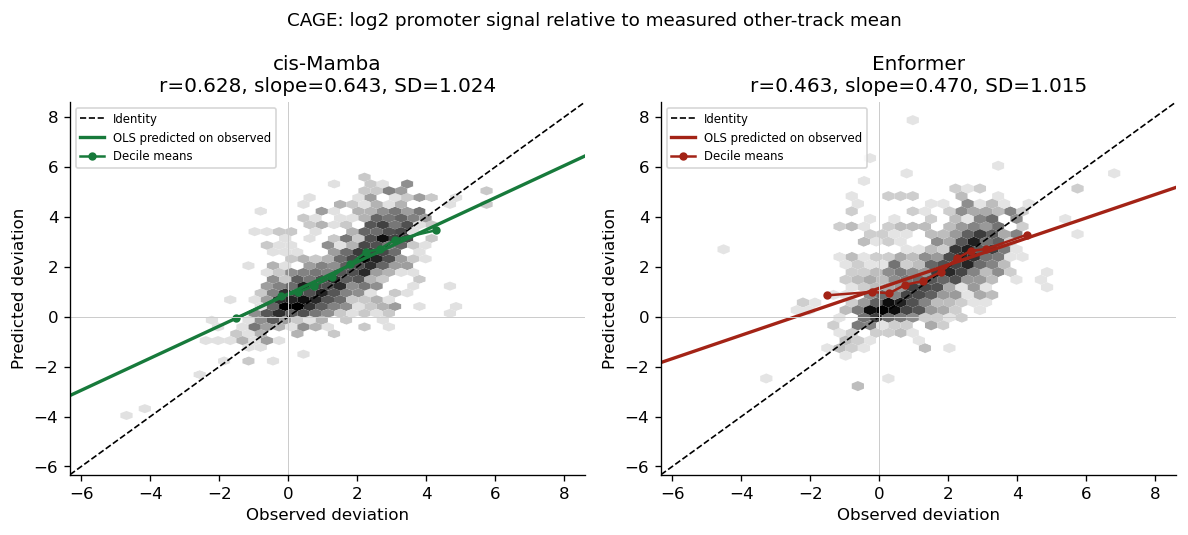

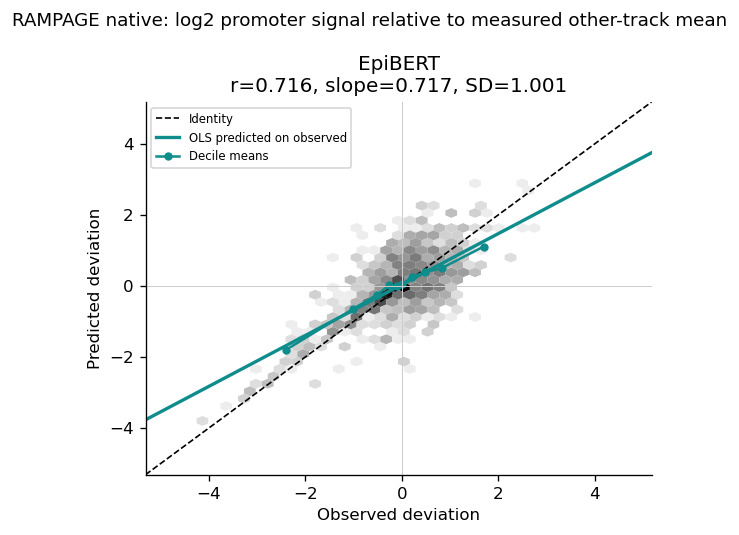

In [3]:
for assay,frame in frames.items():
    figure = scatter_figure(frame,assay,list(inputs[assay]['predictions']))
    stem = 'cage' if assay=='CAGE' else 'rampage'
    figure.savefig(OUT/f'{stem}_deviations.png',bbox_inches='tight',dpi=180)
    plt.show()

## Specificity tails and direction

Thresholds use only observed deviations, identically for every model. Quantile ties can exceed
the nominal fraction; actual gene and block counts are shown. Positive and negative deviations
are separated because a model can miss activation and fail to suppress broadly active promoters
in different ways. The `±1` cutoffs mean one log2 unit on the assay-specific analysis scale.
No accessibility or model-score filter selects this analysis set.

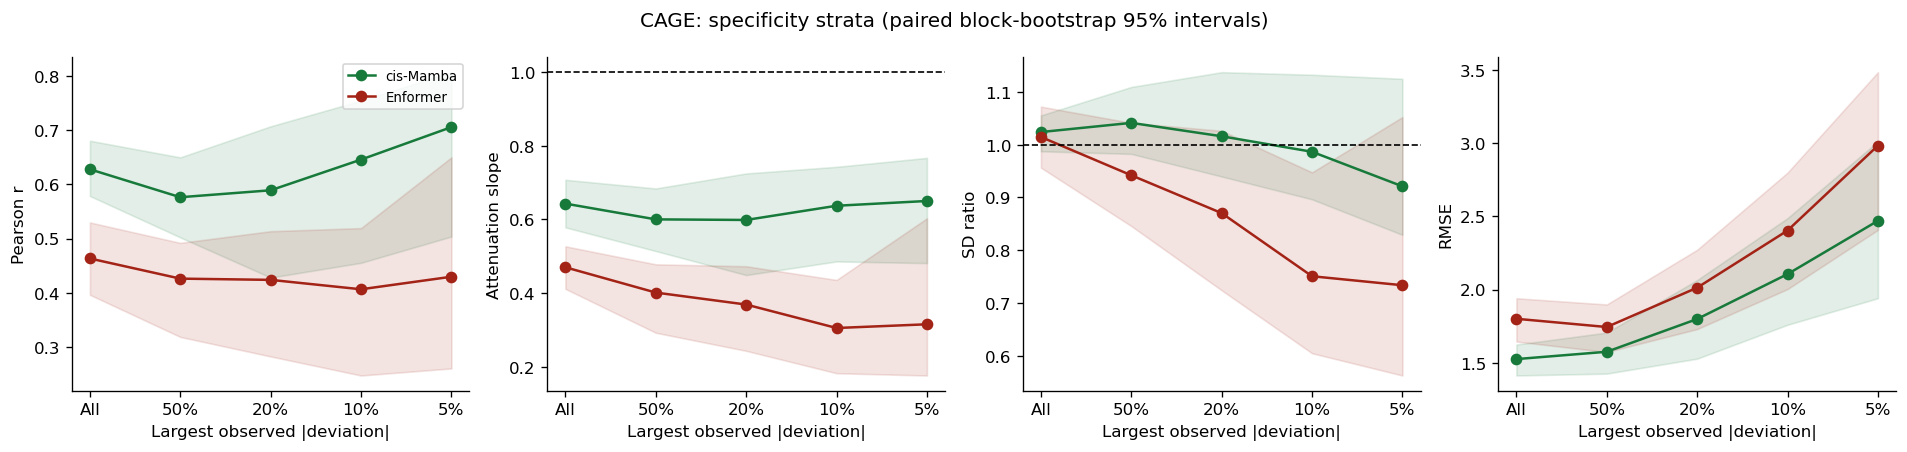

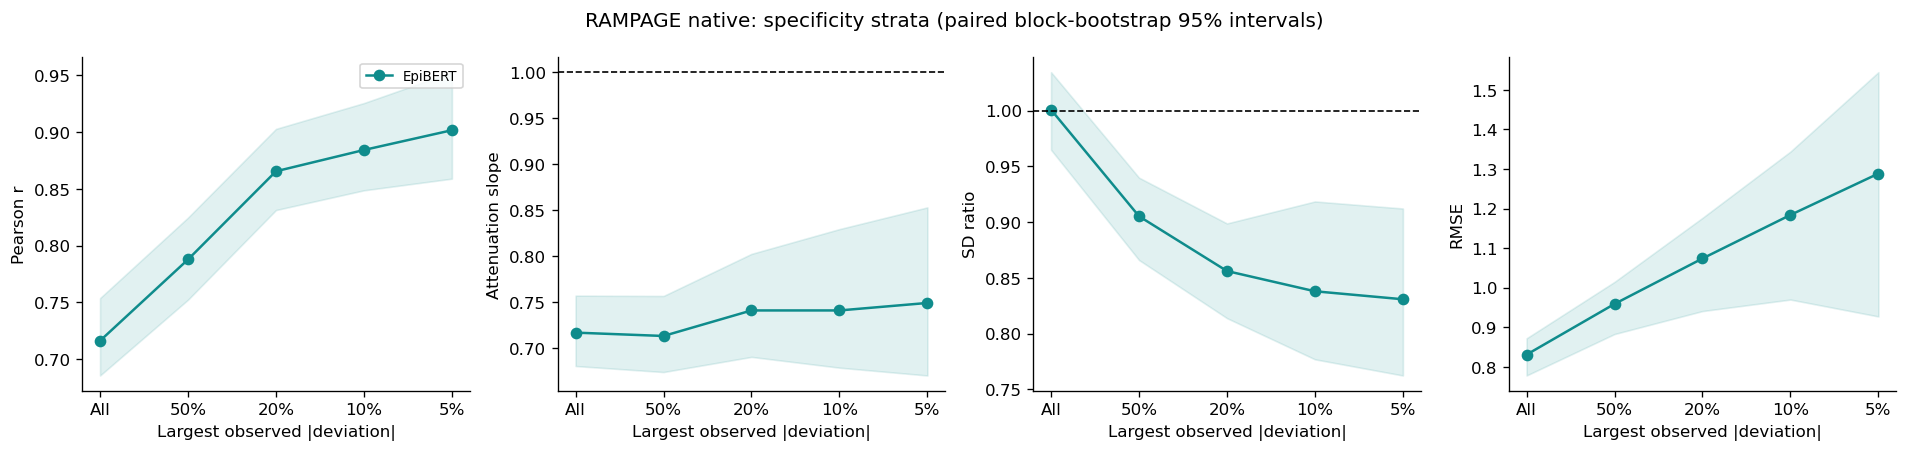

,assay,subset,model,n_genes,n_blocks,pearson,slope,sd_ratio,rmse,bias,sign_accuracy,skill_vs_mean
0,CAGE,All,cis-Mamba,1797,87,0.6278,0.6429,1.0239,1.5258,0.3883,0.8420,0.5346
1,CAGE,All,Enformer,1797,87,0.4631,0.4699,1.0146,1.8008,0.3638,0.8180,0.3517
4,CAGE,Top 50% |d|,cis-Mamba,899,62,0.5763,0.6001,1.0413,1.5758,0.0786,0.9566,0.7312
5,CAGE,Top 50% |d|,Enformer,899,62,0.4259,0.4012,0.9420,1.7447,-0.0681,0.9299,0.6705
8,CAGE,Top 20% |d|,cis-Mamba,360,57,0.5891,0.5985,1.0159,1.7991,-0.3202,0.9667,0.7818
9,CAGE,Top 20% |d|,Enformer,360,57,0.4236,0.3687,0.8703,2.0129,-0.4732,0.9472,0.7269
12,CAGE,Top 10% |d|,cis-Mamba,180,47,0.6458,0.6371,0.9865,2.1056,-0.7006,0.9611,0.7758
13,CAGE,Top 10% |d|,Enformer,180,47,0.4062,0.3049,0.7506,2.4029,-0.6292,0.9278,0.7080
16,CAGE,Top 5% |d|,cis-Mamba,90,37,0.7057,0.6500,0.9210,2.4695,-1.1792,0.9667,0.7682
17,CAGE,Top 5% |d|,Enformer,90,37,0.4294,0.3150,0.7336,2.9823,-1.0473,0.8778,0.6620


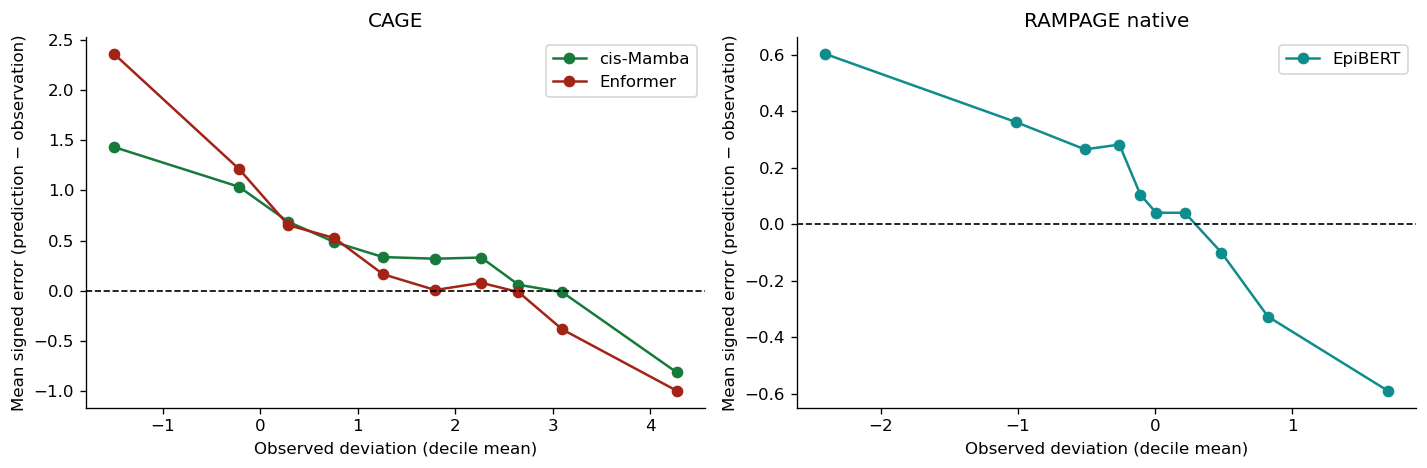

In [4]:
for assay in frames:
    figure = specificity_figure(tables[assay],assay,list(inputs[assay]['predictions']))
    figure.savefig(OUT/('cage_specificity.png' if assay=='CAGE' else 'rampage_specificity.png'),bbox_inches='tight',dpi=180)
    plt.show()
display(scores.loc[scores.model.isin(['cis-Mamba','Enformer','EpiBERT']),
    ['assay','subset','model','n_genes','n_blocks','pearson','slope','sd_ratio','rmse','bias','sign_accuracy','skill_vs_mean']].round(4))
figure = diagnostic_figure(frames)
figure.savefig(OUT/'signed_errors.png',bbox_inches='tight',dpi=180)
plt.show()

## Paired CAGE comparison

Every difference below is **cis-Mamba minus Enformer** on identical promoters and bootstrap
draws. Negative RMSE/MAE differences favor cis-Mamba; positive correlation/skill differences favor it.
A larger slope or SD ratio alone is not necessarily better: the target is one. These are descriptive
95% intervals, not multiplicity-corrected hypothesis tests across all subsets and metrics.

In [5]:
paired = paired_differences(tables['CAGE'],bootstraps['CAGE'])
display(paired[paired.subset.isin(['All','Top 10% |d|','Positive d','Negative d'])].round(4))

,subset,metric,difference,lo,hi,valid_draws,direction
0,All,pearson,0.1647,0.0967,0.2370,1000,higher is better
1,All,rmse,-0.2750,-0.4499,-0.1337,1000,lower is better
2,All,mae,-0.0914,-0.1950,-0.0097,1000,lower is better
3,All,skill_vs_mean,0.1829,0.0858,0.3062,1000,higher is better
4,All,slope,0.1730,0.1047,0.2436,1000,closer to 1 is better; signed difference is no...
5,All,sd_ratio,0.0093,-0.0381,0.0608,1000,closer to 1 is better; signed difference is no...
18,Top 10% |d|,pearson,0.2395,0.0624,0.3733,1000,higher is better
19,Top 10% |d|,rmse,-0.2973,-0.6555,0.0474,1000,lower is better
20,Top 10% |d|,mae,-0.1767,-0.3800,0.0607,1000,lower is better
21,Top 10% |d|,skill_vs_mean,0.0678,-0.0101,0.1512,1000,higher is better


## Sensitivity checks

Vary promoter half-width (256/512/1,024 bp), pseudocount (0.1/1/10), and reference definition
(mean of logs versus log of arithmetic mean). Also exclude overlapping promoters or require
nonzero observed signal; that last selection is explicitly truth-dependent. These are point estimates,
not a search for a favorable specification. All combinations were set before inspecting model scores.
Leave-one-chromosome-out results assess whether a single chromosome determines the CAGE comparison.

In [6]:
sensitivity = sensitivity_table(promoters,inputs)
display(sensitivity[['assay','model','pad','pseudocount','baseline','selection','n_genes',
                     'pearson','slope','sd_ratio','rmse','skill_vs_mean']].round(4))
chromosome_rows=[]
for chromosome in sorted(frames['CAGE'].chrom.unique()):
    frame=frames['CAGE'].loc[frames['CAGE'].chrom!=chromosome]
    mm=metrics(frame.d_obs,frame['cis-Mamba'])
    ee=metrics(frame.d_obs,frame['Enformer'])
    chromosome_rows.append(dict(omitted_chromosome=chromosome,n_genes=len(frame),
        delta_rmse=mm['rmse']-ee['rmse'],delta_pearson=mm['pearson']-ee['pearson']))
chromosome_sensitivity=pd.DataFrame(chromosome_rows)
display(chromosome_sensitivity.round(4))

,assay,model,pad,pseudocount,baseline,selection,n_genes,pearson,slope,sd_ratio,rmse,skill_vs_mean
0,CAGE,cis-Mamba,512,1.0,mean_log,all,1797,0.6278,0.6429,1.0239,1.5258,0.5346
1,CAGE,Enformer,512,1.0,mean_log,all,1797,0.4631,0.4699,1.0146,1.8008,0.3517
2,CAGE,cis-Mamba,256,1.0,mean_log,all,1797,0.6226,0.6442,1.0347,1.5887,0.4869
3,CAGE,Enformer,256,1.0,mean_log,all,1797,0.4615,0.4739,1.0269,1.8832,0.2790
4,CAGE,cis-Mamba,1024,1.0,mean_log,all,1797,0.6106,0.6241,1.0221,1.4773,0.5657
5,CAGE,Enformer,1024,1.0,mean_log,all,1797,0.4302,0.4348,1.0107,1.7338,0.4018
6,CAGE,cis-Mamba,512,0.1,mean_log,all,1797,0.5406,0.5259,0.9727,1.7780,0.5330
7,CAGE,Enformer,512,0.1,mean_log,all,1797,0.3749,0.3782,1.0088,2.0668,0.3690
8,CAGE,cis-Mamba,512,10.0,mean_log,all,1797,0.6987,0.7624,1.0912,1.1431,0.5739
9,CAGE,Enformer,512,10.0,mean_log,all,1797,0.5785,0.5813,1.0048,1.2832,0.4631


,omitted_chromosome,n_genes,delta_rmse,delta_pearson
0,chr1,1792,-0.2754,0.1651
1,chr10,1792,-0.2748,0.1642
2,chr11,1676,-0.2916,0.1712
3,chr12,1791,-0.2760,0.1645
4,chr14,1197,-0.3051,0.1782
5,chr15,1779,-0.2665,0.1607
6,chr19,1183,-0.1748,0.1031
7,chr2,1796,-0.2752,0.1648
8,chr22,1745,-0.2837,0.1676
9,chr3,1679,-0.2931,0.1718


## Interpretation of this run

The next cell reports the actual results, regardless of whether they support the original hypothesis.

In [7]:
all_scores=scores[scores.subset=='All'].set_index(['assay','model'])
sentences=[]
for assay,names in [('CAGE',['cis-Mamba','Enformer']),('RAMPAGE native',['EpiBERT'])]:
    for name in names:
        s=all_scores.loc[(assay,name)]
        sentences.append(f"**{assay}, {name}:** deviation r={s.pearson:.3f}; slope={s.slope:.3f} "
                         f"(95% CI {s.slope_lo:.3f}–{s.slope_hi:.3f}); SD ratio={s.sd_ratio:.3f}; "
                         f"RMSE={s.rmse:.3f}; skill over the measured reference mean={s.skill_vs_mean:.3f}.")
d=paired[(paired.subset=='All')&(paired.metric=='rmse')].iloc[0]
winner='cis-Mamba' if d.difference<0 else 'Enformer'
confidence='the paired interval excludes zero' if d.lo*d.hi>0 else 'the paired interval includes zero'
sentences.append(f"**CAGE error comparison:** {winner} has lower point-estimate RMSE. "
                 f"cis-Mamba − Enformer = {d.difference:.3f} (95% CI {d.lo:.3f}–{d.hi:.3f}); {confidence}.")
sentences.append('**Mechanism:** all three global SD ratios are close to one. The lower slopes therefore '
                 'do not demonstrate globally compressed deviation variance. Since slope = correlation × SD ratio, '
                 'the CAGE slope difference is largely a difference in alignment with observed deviations. '
                 'Conditional attenuation of extremes and suppression failures can still occur despite matching overall spread.')
for subset in ['Negative d','Positive d','Top 10% |d|']:
    d=paired[(paired.subset==subset)&(paired.metric=='rmse')].iloc[0]
    sentences.append(f"**{subset}:** CAGE RMSE difference (cis-Mamba − Enformer) is {d.difference:.3f} "
                     f"(95% CI {d.lo:.3f}–{d.hi:.3f}).")
sentences.append('The strongest CAGE advantage is for promoters below the reference mean. Both models '
                 'nevertheless overpredict that group and have negative skill versus the measured-reference predictor '
                 'within that stratum. The positive-deviation and top-10% RMSE intervals include zero. '
                 'cis-Mamba has lower RMSE in every reported CAGE readout/pseudocount/reference sensitivity '
                 'and every leave-one-chromosome-out ')
sentences.append('These results assess GM12878 promoter expression on this gene set. They do not establish '
                 'a causal benefit of single-task training, raw-RAMPAGE amplitude fidelity, unseen-cell generalization, '
                 'or variant-effect prediction. A publication claim should depend on the tail and sensitivity results as well as global scores.')
summary='\n\n'.join(sentences)
display(Markdown(summary))

Out[7]: 2002


**CAGE, cis-Mamba:** deviation r=0.628; slope=0.643 (95% CI 0.578–0.708); SD ratio=1.024; RMSE=1.526; skill over the measured reference mean=0.535.

**CAGE, Enformer:** deviation r=0.463; slope=0.470 (95% CI 0.411–0.527); SD ratio=1.015; RMSE=1.801; skill over the measured reference mean=0.352.

**RAMPAGE native, EpiBERT:** deviation r=0.716; slope=0.717 (95% CI 0.680–0.757); SD ratio=1.001; RMSE=0.830; skill over the measured reference mean=0.433.

**CAGE error comparison:** cis-Mamba has lower point-estimate RMSE. cis-Mamba − Enformer = -0.275 (95% CI -0.450–-0.134); the paired interval excludes zero.

**Mechanism:** all three global SD ratios are close to one. The lower slopes therefore do not demonstrate globally compressed deviation variance. Since slope = correlation × SD ratio, the CAGE slope difference is largely a difference in alignment with observed deviations. Conditional attenuation of extremes and suppression failures can still occur despite matching overall spread.

**Negative d:** CAGE RMSE difference (cis-Mamba − Enformer) is -0.940 (95% CI -1.342–-0.538).

**Positive d:** CAGE RMSE difference (cis-Mamba − Enformer) is -0.032 (95% CI -0.147–0.068).

**Top 10% |d|:** CAGE RMSE difference (cis-Mamba − Enformer) is -0.297 (95% CI -0.656–0.047).

The strongest CAGE advantage is for promoters below the reference mean. Both models nevertheless overpredict that group and have negative skill versus the measured-reference predictor within that stratum. The positive-deviation and top-10% RMSE intervals include zero. cis-Mamba has lower RMSE in every reported CAGE readout/pseudocount/reference sensitivity and every leave-one-chromosome-out analysis.

These results assess GM12878 promoter expression on this gene set. They do not establish a causal benefit of single-task training, raw-RAMPAGE amplitude fidelity, unseen-cell generalization, or variant-effect prediction. A publication claim should depend on the tail and sensitivity results as well as global scores.

## What would strengthen a follow-up paper

Use matched single-cell versus multicell training within the same architecture, with matched
**input modalities**, loss, context, capacity, checkpoint selection, and multiple seeds. Include
a sequence-only cis-Mamba ablation and/or a matched accessibility-conditioned multitask model.
Repeat in several biologically
distinct cell types. Obtain replicate-level measurements to estimate reliability and select
specificity tails independently of the evaluated measurement. Balance reference panels by cell type,
check assay normalization, and test calibration learned on validation loci without modifying test outputs.

The literature's full predicted-panel mean centering / across-cell correlations cannot be reproduced
from the available single-GM12878 prediction arrays. Quantile-normalizing this single track would not
reproduce AlphaGenome's benchmark, so it is not presented as such. This notebook's measured-reference
correlation is related but has a different estimand. Generate matched all-cell predictions for the
multitask models, and matched specialist models for multiple cells, to add that analysis fairly.

The historical mapping in `evals/eval_joint_expression_old.py` associates `GM12878_no_mlm`
with `outputs/2025-04-14/18-29-44-495215/checkpoints/06-val_loss=-0.45494.ckpt`.
That run's `.hydra/config.yaml` specifies `GM12878_DNase.npz` as the input accessibility,
`GM12878CAGE.npz` as the expression target, `acc_mlm: 0`, and CAGE Poisson fine-tuning.
`Evals.__call__` feeds sequence and accessibility to `JointCNN`. This is evidence of
accessibility-conditioned CAGE fine-tuning, not a cryptographic prediction-to-checkpoint manifest;
confirm the exact export provenance before publication. Genomic holdouts do not make GM12878 a held-out cell type.
EpiBERT's local prediction script uses full measured ATAC and a GM12878 motif vector with forward
inference; it is not the paper's stochastic masked evaluation. No model was retrained here.

## Literature audit and reproducibility

- [Kathail et al., Bioinformatics 2026](https://academic.oup.com/bioinformatics/article/42/9/btag626/8767764),
  §2.3: logFC over cell-type average and correlation across tracks support the proposal's motivation.
  They are not identical to the common observed-reference diagnostic here.
- [AlphaGenome, Nature 2026](https://www.nature.com/articles/s41586-025-10014-0):
  normalized, mean-subtracted expression comparisons motivate retaining correlation alongside magnitude metrics.
- [scooby, Nature Methods 2025](https://www.nature.com/articles/s41592-025-02854-5):
  gene/cell mean removal is a relevant precedent, not a matched GM12878 comparator.
- [EpiBERT, Cell Genomics 2025](https://pmc.ncbi.nlm.nih.gov/articles/PMC11872434/), Fig. 4:
  its expression comparison used **Enformer fine-tuned for RAMPAGE**. The local CAGE Enformer
  predictions are not that comparator. EpiBERT is accessibility-conditioned and should be described accordingly.

Rebuild caches from this directory (`cage` first; it writes `promoters.tsv`):

```bash
/data1/lesliec/sarthak/caduceus/.pixi/envs/default/bin/python prepare_model8.py cage
/data1/lesliec/sarthak/EpiBERT/.pixi/envs/default/bin/python prepare_model8.py rampage
/data1/lesliec/sarthak/caduceus/.pixi/envs/default/bin/python prepare_model8.py enformer_extra
/data1/lesliec/sarthak/caduceus/.pixi/envs/default/bin/python prepare_model8.py borzoi
```

Then run all notebook cells using the caduceus environment. Source files are read-only. The CAGE reader directly
decodes the legacy Zarr v2 chunks because installed Zarr 3 hangs opening that store. Numerical checks
verify the attenuation example, metric identities, and block bootstrap against explicitly repeated samples.
The RAMPAGE transform was also checked against TensorFlow's `conv1d` implementation (maximum
absolute difference 1.91e-6 on a synthetic input including clipping and zero values).

---
# Additional model comparisons (appended)

The original analysis and figures above are preserved. These sections add six Enformer-grid arms
and an independent Borzoi-grid experiment using the **same metric definitions**, 1,000 paired
genomic-block bootstrap draws, specificity strata, and sensitivity settings. Their input caches and figures are in
`comparing_model8_results/extensions/`.

## A. cis-Mamba ablations and retrained Enformers

The same 1,797 genes, promoters, 128-bp grid, observed CAGE panel, and reference mean as above:

- Original cis-Mamba and pretrained Enformer, repeated as anchors in these new figures.
- cis-Mamba with no pretraining, and cis-Mamba trained on eight cell types.
- Retrained Enformer: one cell type at 768 or 1,536 channels, 16 cell types, and 42 cell types.

Every added arm's saved GM12878 targets were checked against the reference **across all bins**.
For multitrack retrained outputs, the accompanying track CSV identifies the GM12878 CAGE column
and verifies target index 5110. No independent rescaling is fitted. Cell-type counts are not
necessarily task counts: retrained models may jointly predict accessibility and CAGE. The input,
pretraining, width, and task differences mean this is a comparison of saved runs rather than a
fully controlled causal estimate of the effect of task count.

In [ ]:
# Helpers for the additional comparisons; reuse the metric functions defined above.
EXT_OUT=OUT/'extensions'
EXTRA_COLORS={'cis-Mamba (no pretraining)':'#63BF82','cis-Mamba (8 CTs)':'#9BD9AE',
 'Enformer retrained (1 CT, 768ch)':'#E2603F','Enformer retrained (1 CT, 1536ch)':'#C93B22',
 'Enformer retrained (16 CTs)':'#DA8078','Enformer retrained (42 CTs)':'#A36860',
 'cis-Mamba (Borzoi grid)':'#177A3B','Borzoi pretrained':'#12456F','Borzoi LoRA':'#7FB3DE',
 'Borzoi full FT':'#2E7EBD','Borzoi from scratch':'#1B639C'}
COLORS.update(EXTRA_COLORS)


def load_extensions():
    promoters,original=load_inputs()
    cage=original['CAGE']
    extras=np.load(EXT_OUT/'enformer_extra_inputs.npz')
    cage['predictions'].update({name:extras[name] for name in extras.files})
    bp=pd.read_csv(EXT_OUT/'borzoi_promoters.tsv',sep='\t')
    bi=np.load(EXT_OUT/'borzoi_inputs.npz')
    borzoi=dict(measured=bi['measured'],gm=435,predictions={name:bi[name] for name in bi.files if name!='measured'})
    for p,data in [(promoters,cage),(bp,borzoi)]:
        assert len(p)==len(data['measured'])
        assert np.isfinite(data['measured']).all() and (data['measured']>=0).all()
        assert p.groupby('pad').gene_id.nunique().nunique()==1
    return {'Enformer-grid CAGE':(promoters,cage),'Borzoi-grid CAGE':(bp,borzoi)}


def paired_comparison(table,draws,left,right):
    rows=[]
    for subset in table.subset.unique():
        t=table[table.subset==subset].set_index('model')
        for metric in ['pearson','slope','sd_ratio','rmse','mae','skill_vs_mean']:
            delta=draws[subset,left][metric]-draws[subset,right][metric]
            good=np.isfinite(delta)
            lo,hi=np.quantile(delta[good],[.025,.975]) if good.sum()>=len(delta)*.9 else [np.nan,np.nan]
            rows.append(dict(subset=subset,left=left,right=right,metric=metric,
                             difference=t.loc[left,metric]-t.loc[right,metric],lo=lo,hi=hi,
                             valid_draws=int(good.sum())))
    return pd.DataFrame(rows)


def forest(table,models,title,subset='All'):
    t=table[table.subset==subset].set_index('model').loc[models]
    fig,axes=plt.subplots(1,4,figsize=(15,max(3.5,.43*len(models)+1.2)),sharey=True)
    for ax,metric,label,ideal in zip(axes,['pearson','slope','sd_ratio','rmse'],
                                   ['Deviation Pearson r','Attenuation slope','SD ratio','RMSE'],[None,1,1,None]):
        for i,model in enumerate(models):
            row=t.loc[model]
            ax.plot([row[metric+'_lo'],row[metric+'_hi']],[i,i],color=COLORS[model],lw=2)
            ax.plot(row[metric],i,'o',color=COLORS[model],ms=6)
        if ideal is not None:ax.axvline(ideal,color='black',ls='--',lw=1)
        ax.set_xlabel(label)
        ax.set_yticks(range(len(models)))
    axes[0].set_yticklabels(models,fontsize=9)
    axes[0].invert_yaxis()
    fig.suptitle(f'{title} · {subset} · paired block-bootstrap 95% intervals')
    fig.tight_layout()
    return fig


def scatter_grid(frame,models,title):
    ncols=min(3,len(models));nrows=int(np.ceil(len(models)/ncols))
    fig,axes=plt.subplots(nrows,ncols,figsize=(4.6*ncols,4*nrows),squeeze=False,sharex=True,sharey=True)
    values=np.concatenate([frame.d_obs.to_numpy()]+[frame[m].to_numpy() for m in models])
    lim=[values.min()-.2,values.max()+.2]
    for ax,model in zip(axes.flat,models):
        x,y=frame.d_obs.to_numpy(),frame[model].to_numpy();m=metrics(x,y)
        ax.hexbin(x,y,gridsize=35,mincnt=1,bins='log',cmap='Greys',linewidths=0)
        ax.plot(lim,lim,'k--',lw=1)
        ax.plot(lim,m['intercept']+m['slope']*np.array(lim),color=COLORS[model],lw=2)
        groups=np.array_split(np.argsort(x),10)
        ax.plot([x[g].mean() for g in groups],[y[g].mean() for g in groups],'o-',color=COLORS[model],ms=3)
        ax.axhline(0,color='.8',lw=.6);ax.axvline(0,color='.8',lw=.6)
        ax.set(xlim=lim,ylim=lim,title=f"{model}\nr={m['pearson']:.3f}; slope={m['slope']:.3f}")
        ax.set_xlabel('Observed deviation');ax.set_ylabel('Predicted deviation')
    for ax in list(axes.flat)[len(models):]:ax.set_visible(False)
    fig.suptitle(title+' · shared limits; identity dashed; OLS and decile means colored',fontsize=11)
    fig.tight_layout()
    return fig


def specificity(table,assay,models):
    fig=specificity_figure(table,assay,models)
    handles,labels=fig.axes[0].get_legend_handles_labels()
    fig.axes[0].get_legend().remove()
    fig.set_size_inches(16,4.8)
    fig.legend(handles,labels,loc='lower center',ncol=3,fontsize=9,frameon=False)
    fig.tight_layout(rect=(0,.14,1,.94))
    return fig


def run_section(assay,p,data,stem):
    frame=make_frame(p,data)
    models=list(data['predictions'])
    table,draws=evaluate(frame,assay,models+['Other-track mean','Zero expression control'])
    base='Enformer' if stem=='enformer' else 'Borzoi pretrained'
    cis='cis-Mamba' if stem=='enformer' else 'cis-Mamba (Borzoi grid)'
    pairs=[(model,base) for model in models if model!=base]
    pairs += [(cis,model) for model in models if model not in [cis,base]]
    comparisons=pd.concat([paired_comparison(table,draws,left,right) for left,right in pairs],ignore_index=True)
    sensitivity=sensitivity_table(p,{assay:data})
    if stem=='borzoi':
        rows=[]
        for selection,mask in [('strict_no_input_label_overlap',frame.strict_no_input_label_overlap),
                               ('plus_strand',frame.strand=='+'),('minus_strand',frame.strand=='-')]:
            for model in models:
                f=frame.loc[mask]
                rows.append(dict(assay=assay,model=model,pad=512,pseudocount=1.,baseline='mean_log',
                                 selection=selection,n_genes=len(f),**metrics(f.d_obs,f[model])))
        sensitivity=pd.concat([sensitivity,pd.DataFrame(rows)],ignore_index=True)
    return frame,table,comparisons,sensitivity

In [8]:
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
EXT_INPUTS=load_extensions()
E_PROMOTERS,E_DATA=EXT_INPUTS['Enformer-grid CAGE']
E_MODELS=list(E_DATA['predictions'])
E_FRAME,E_TABLE,E_PAIRS,E_SENS=run_section('Enformer-grid CAGE',E_PROMOTERS,E_DATA,'enformer')
# The two original arms must reproduce the existing all-gene results exactly.
E_ORIGINAL=scores
for name in ['cis-Mamba','Enformer']:
    previous=E_ORIGINAL[(E_ORIGINAL.assay=='CAGE')&(E_ORIGINAL.model==name)&(E_ORIGINAL.subset=='All')].iloc[0]
    current=E_TABLE[(E_TABLE.model==name)&(E_TABLE.subset=='All')].iloc[0]
    for metric in ['pearson','spearman','slope','sd_ratio','rmse','mae','skill_vs_mean']:
        assert np.isclose(previous[metric],current[metric],rtol=0,atol=1e-12), (name,metric)
print('Original Enformer-grid anchor scores reproduced; all eight arms use identical genes.')
EXT_COLUMNS=['model','n_genes','expression_pearson','pearson','spearman','slope','sd_ratio','rmse','bias','skill_vs_mean']
display(E_TABLE.loc[(E_TABLE.subset=='All')&E_TABLE.model.isin(E_MODELS),EXT_COLUMNS].round(4))

Original Enformer-grid anchor scores reproduced; all eight arms use identical genes.


,model,n_genes,expression_pearson,pearson,spearman,slope,sd_ratio,rmse,bias,skill_vs_mean
0,cis-Mamba,1797,0.9100,0.6278,0.6333,0.6429,1.0239,1.5258,0.3883,0.5346
1,Enformer,1797,0.8705,0.4631,0.5215,0.4699,1.0146,1.8008,0.3638,0.3517
2,cis-Mamba (no pretraining),1797,0.8849,0.5461,0.5712,0.5797,1.0617,1.7023,0.3681,0.4207
3,cis-Mamba (8 CTs),1797,0.9098,0.5960,0.6089,0.5543,0.9301,1.4837,0.2052,0.5599
4,"Enformer retrained (1 CT, 768ch)",1797,0.7634,0.1458,0.1875,0.1565,1.0730,2.5532,1.1275,-0.3031
5,"Enformer retrained (1 CT, 1536ch)",1797,0.8046,0.2564,0.3318,0.2708,1.0563,2.1823,0.5186,0.0480
6,Enformer retrained (16 CTs),1797,0.8004,0.2073,0.2518,0.2065,0.9962,2.2655,0.7901,-0.0260
7,Enformer retrained (42 CTs),1797,0.7792,0.1409,0.1763,0.1414,1.0034,2.5434,1.2439,-0.2932


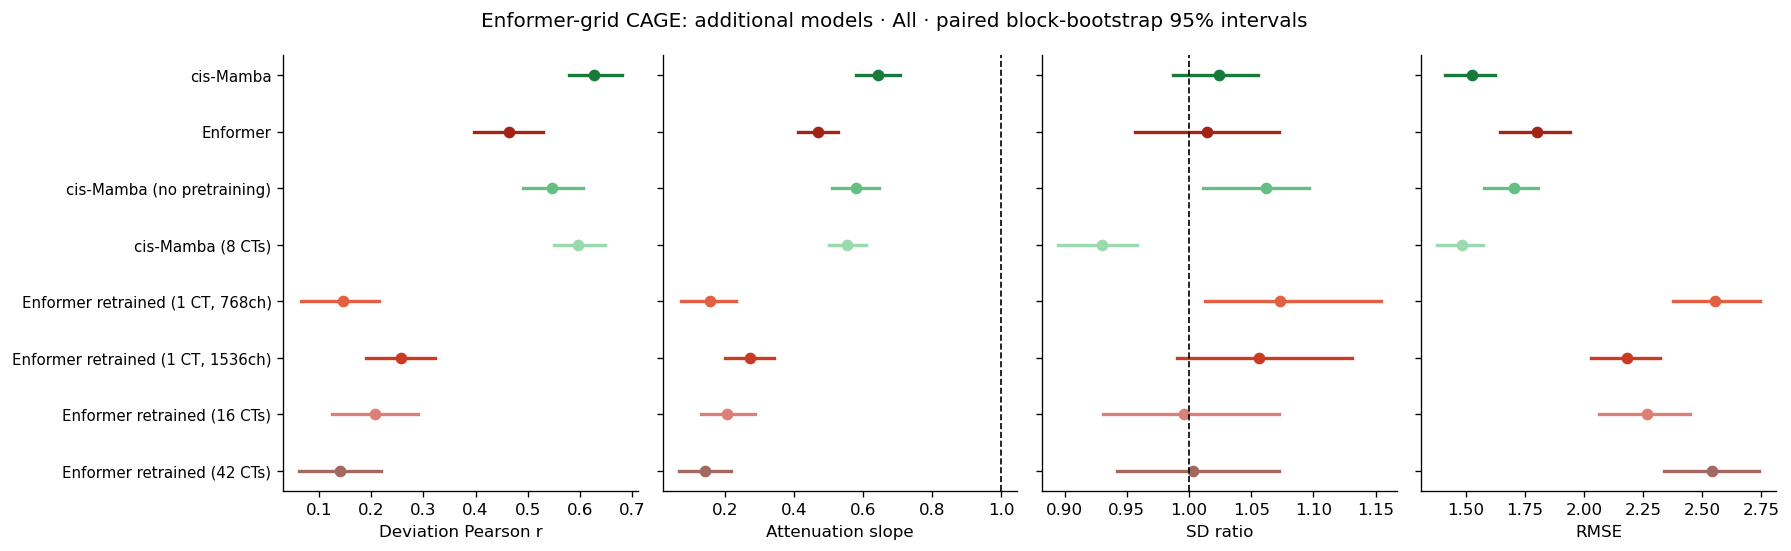

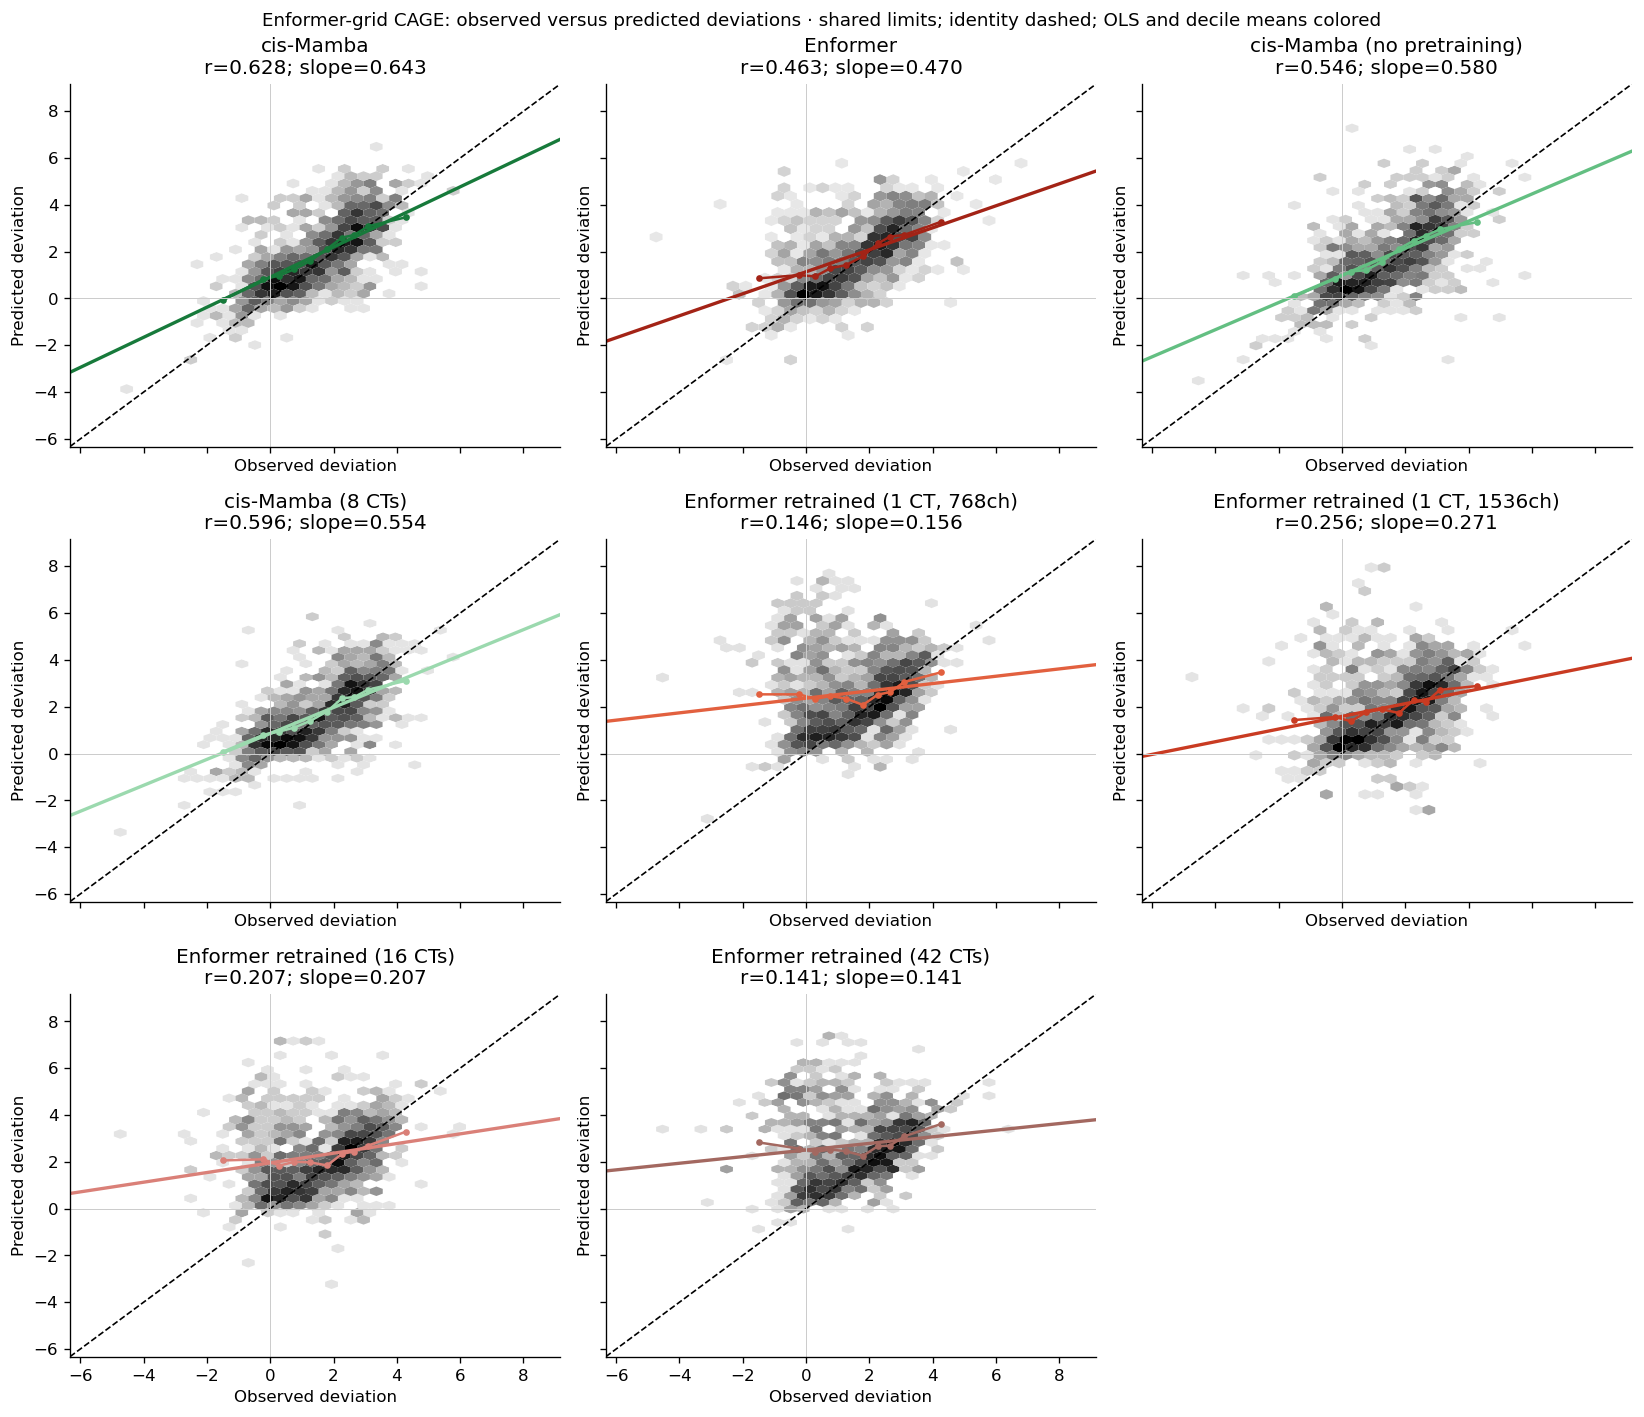

In [9]:
E_FIG=forest(E_TABLE,E_MODELS,'Enformer-grid CAGE: additional models')
E_FIG.savefig(EXT_OUT/'enformer_all_models.png',dpi=180,bbox_inches='tight')
plt.show()
E_FIG=scatter_grid(E_FRAME,E_MODELS,'Enformer-grid CAGE: observed versus predicted deviations')
E_FIG.savefig(EXT_OUT/'enformer_all_scatter.png',dpi=160,bbox_inches='tight')
plt.show()

### Specificity and paired comparisons

The next plots split the model families for readability and repeat the same anchors. Tables report
differences as **left minus right**; negative RMSE favors the left model. Slope and SD ratio should
be judged by proximity to one, not by which is larger. All comparisons use matched bootstrap draws;
intervals are descriptive and have not been corrected for multiple comparisons.

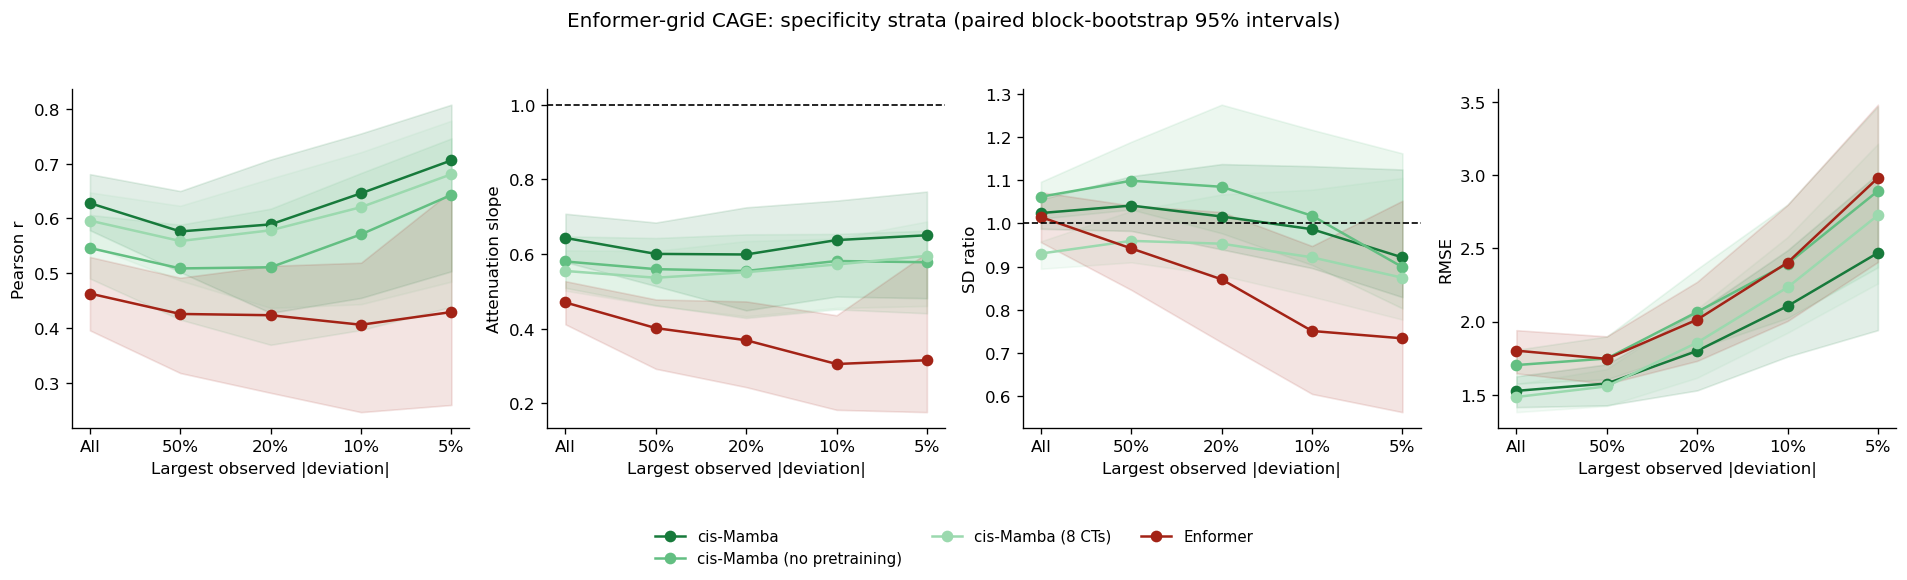

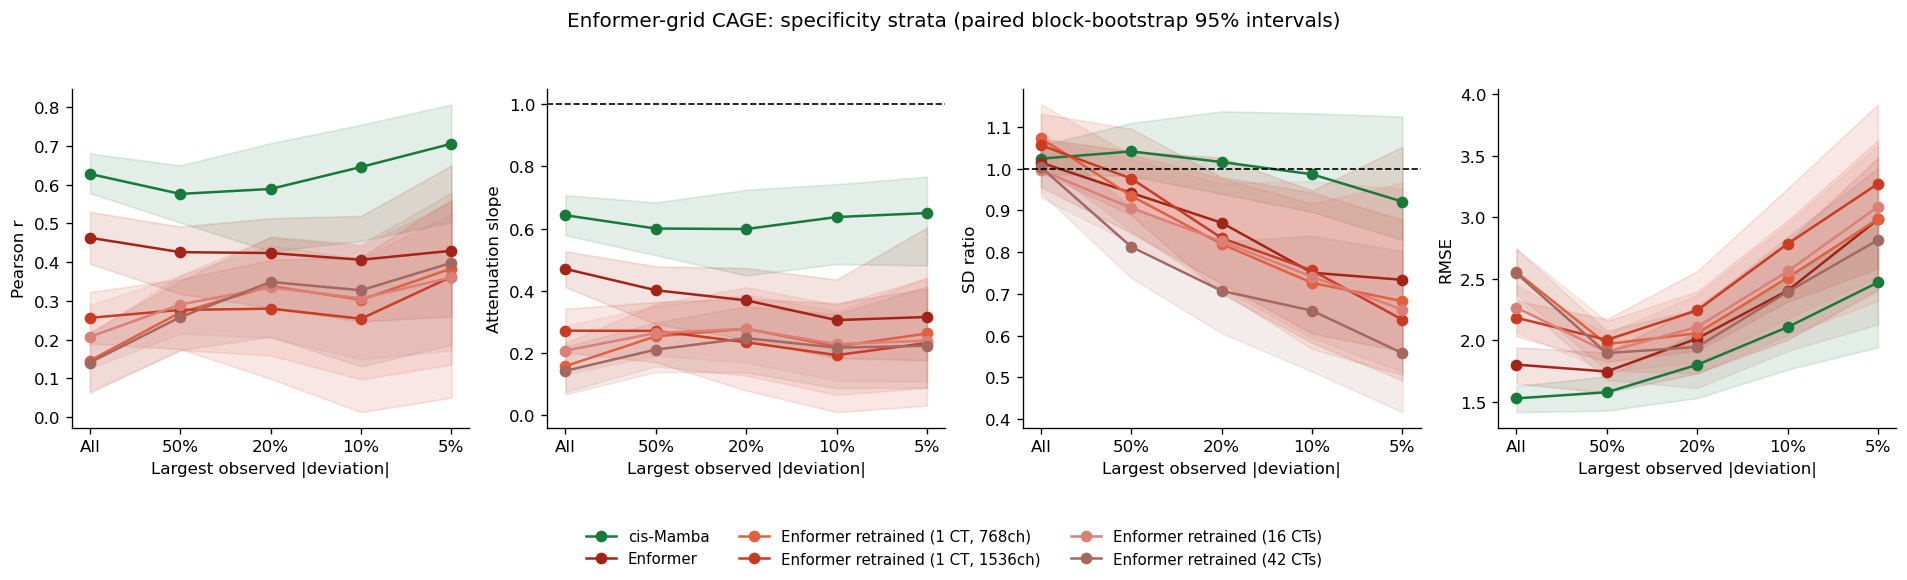

,subset,left,right,metric,difference,lo,hi,valid_draws
0,All,cis-Mamba,Enformer,pearson,0.1647,0.0967,0.2370,1000
3,All,cis-Mamba,Enformer,rmse,-0.2750,-0.4499,-0.1337,1000
18,Top 10% |d|,cis-Mamba,Enformer,pearson,0.2395,0.0624,0.3733,1000
21,Top 10% |d|,cis-Mamba,Enformer,rmse,-0.2973,-0.6555,0.0474,1000
36,Negative d,cis-Mamba,Enformer,pearson,0.3681,0.1930,0.5839,1000
...,...,...,...,...,...,...,...,...
651,All,cis-Mamba,Enformer retrained (42 CTs),rmse,-1.0176,-1.2561,-0.8196,1000
666,Top 10% |d|,cis-Mamba,Enformer retrained (42 CTs),pearson,0.3183,0.1453,0.4775,1000
669,Top 10% |d|,cis-Mamba,Enformer retrained (42 CTs),rmse,-0.2868,-0.7024,0.1633,1000
684,Negative d,cis-Mamba,Enformer retrained (42 CTs),pearson,0.3777,0.2433,0.5311,1000


,model,pad,pseudocount,baseline,selection,n_genes,pearson,slope,sd_ratio,rmse
0,cis-Mamba,512,1.0,mean_log,all,1797,0.6278,0.6429,1.0239,1.5258
1,Enformer,512,1.0,mean_log,all,1797,0.4631,0.4699,1.0146,1.8008
2,cis-Mamba (no pretraining),512,1.0,mean_log,all,1797,0.5461,0.5797,1.0617,1.7023
3,cis-Mamba (8 CTs),512,1.0,mean_log,all,1797,0.5960,0.5543,0.9301,1.4837
4,"Enformer retrained (1 CT, 768ch)",512,1.0,mean_log,all,1797,0.1458,0.1565,1.0730,2.5532
...,...,...,...,...,...,...,...,...,...,...
59,cis-Mamba (8 CTs),512,1.0,mean_log,nonzero_observed,1782,0.5938,0.5540,0.9329,1.4863
60,"Enformer retrained (1 CT, 768ch)",512,1.0,mean_log,nonzero_observed,1782,0.1444,0.1552,1.0746,2.5487
61,"Enformer retrained (1 CT, 1536ch)",512,1.0,mean_log,nonzero_observed,1782,0.2536,0.2684,1.0587,2.1836
62,Enformer retrained (16 CTs),512,1.0,mean_log,nonzero_observed,1782,0.2068,0.2060,0.9957,2.2587


In [10]:
E_FAMILIES=[['cis-Mamba','cis-Mamba (no pretraining)','cis-Mamba (8 CTs)','Enformer'],
            ['cis-Mamba','Enformer']+[m for m in E_MODELS if m.startswith('Enformer retrained')]]
for i,names in enumerate(E_FAMILIES):
    E_FIG=specificity(E_TABLE,'Enformer-grid CAGE',names)
    E_FIG.savefig(EXT_OUT/f'enformer_specificity_family{i+1}.png',dpi=160,bbox_inches='tight')
    plt.show()
display(E_PAIRS[(E_PAIRS.subset.isin(['All','Top 10% |d|','Negative d'])) &
                (E_PAIRS.metric.isin(['rmse','pearson']))].round(4))
display(E_SENS[['model','pad','pseudocount','baseline','selection','n_genes','pearson','slope','sd_ratio','rmse']].round(4))

## B. Borzoi CAGE: pretrained, fine-tuned, and from scratch

This is a separate experiment on Borzoi **fold3**, using the cis-Mamba checkpoint trained on the
Borzoi CAGE data (epoch 4, the arm selected in the existing figure pipeline). It is not the original
Enformer-grid cis-Mamba checkpoint. Comparators are pretrained Borzoi, Borzoi LoRA, full fine-tuning,
and training from scratch. The latter is labeled separately from fine-tuning.

The source grid is 6,888 × 6,144 bins at 32 bp, with separate plus/minus CAGE tracks. Use the
annotated gene's strand throughout: its GM12878 signal and reference panel use the same strand.
The primary promoter sums 32 bins whose centers lie within TSS ±512 bp, then applies `log2(sum+1)`.
The reference is the mean log signal of the **637 other same-strand CAGE datasets**. Values remain
on the deposited, processed Borzoi training-target scale; no inverse transform, smoothing, z-score,
or test-fitted calibration is introduced. Do not compare absolute scores directly with the earlier
unstranded 128-bp experiment, which has a different split and gene set.

Use the prior Borzoi figure pipeline's overlap rule: exclude a test region when its 524-kb input
overlaps a training target span by more than 20% of the 196,608-bp output span. Independently verify
zero overlap between test and training **target spans**. This rule still allows some input/label
overlap; the sensitivity table also removes every gene whose chosen input overlaps any training
target. Annotation-based transcript selection, window-size sensitivities, and bootstrap blocks
follow the original notebook, with strand-aware promoter ambiguity checks.

Checks: metadata identifies CAGE tracks 0–1275 and GM12878 at 870/871; all bins of every selected
source region match the saved cis-Mamba targets exactly. Pretrained GM12878 extraction is checked
against the original full prediction store on five regions. Fine-tuned channel order follows the
exporter: CAGE+, CAGE−, DNase; only the first two channels are scored. These Borzoi runs take DNA
as input and fine-tune three output tracks; DNase is an output, not an input, in those runs.
The cis-Mamba arm is accessibility-conditioned, so the modality caveat still applies.

1,934 genes; 1,367 selected regions; 160 genomic bootstrap blocks; 1,902 genes pass the stricter overlap check.


,model,n_genes,expression_pearson,pearson,spearman,slope,sd_ratio,rmse,bias,skill_vs_mean
0,cis-Mamba (Borzoi grid),1934,0.9096,0.6436,0.6307,0.6001,0.9324,1.5075,0.2313,0.5821
1,Borzoi pretrained,1934,0.8616,0.3433,0.3699,0.2335,0.6804,1.8888,0.5157,0.3439
2,Borzoi LoRA,1934,0.8886,0.5431,0.5737,0.4718,0.8686,1.6620,0.2713,0.4920
3,Borzoi full FT,1934,0.8918,0.5771,0.6058,0.5504,0.9536,1.6375,-0.0138,0.5069
4,Borzoi from scratch,1934,0.8288,0.3584,0.4095,0.3482,0.9716,2.0375,0.1224,0.2366


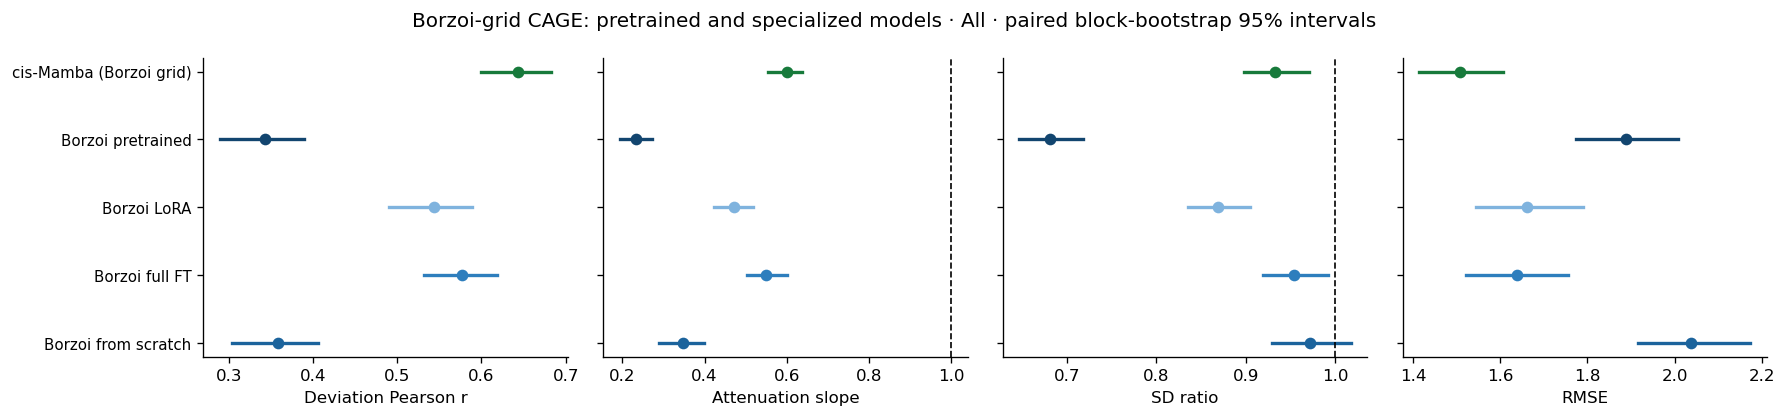

In [11]:
B_PROMOTERS,B_DATA=EXT_INPUTS['Borzoi-grid CAGE']
B_MODELS=list(B_DATA['predictions'])
B_FRAME,B_TABLE,B_PAIRS,B_SENS=run_section('Borzoi-grid CAGE',B_PROMOTERS,B_DATA,'borzoi')
print(f'{len(B_FRAME):,} genes; {B_FRAME.borzoi_row.nunique():,} selected regions; '
      f'{B_FRAME.block.nunique()} genomic bootstrap blocks; '
      f'{B_FRAME.strict_no_input_label_overlap.sum():,} genes pass the stricter overlap check.')
display(B_TABLE.loc[(B_TABLE.subset=='All')&B_TABLE.model.isin(B_MODELS),EXT_COLUMNS].round(4))
B_FIG=forest(B_TABLE,B_MODELS,'Borzoi-grid CAGE: pretrained and specialized models')
B_FIG.savefig(EXT_OUT/'borzoi_all_models.png',dpi=180,bbox_inches='tight')
plt.show()

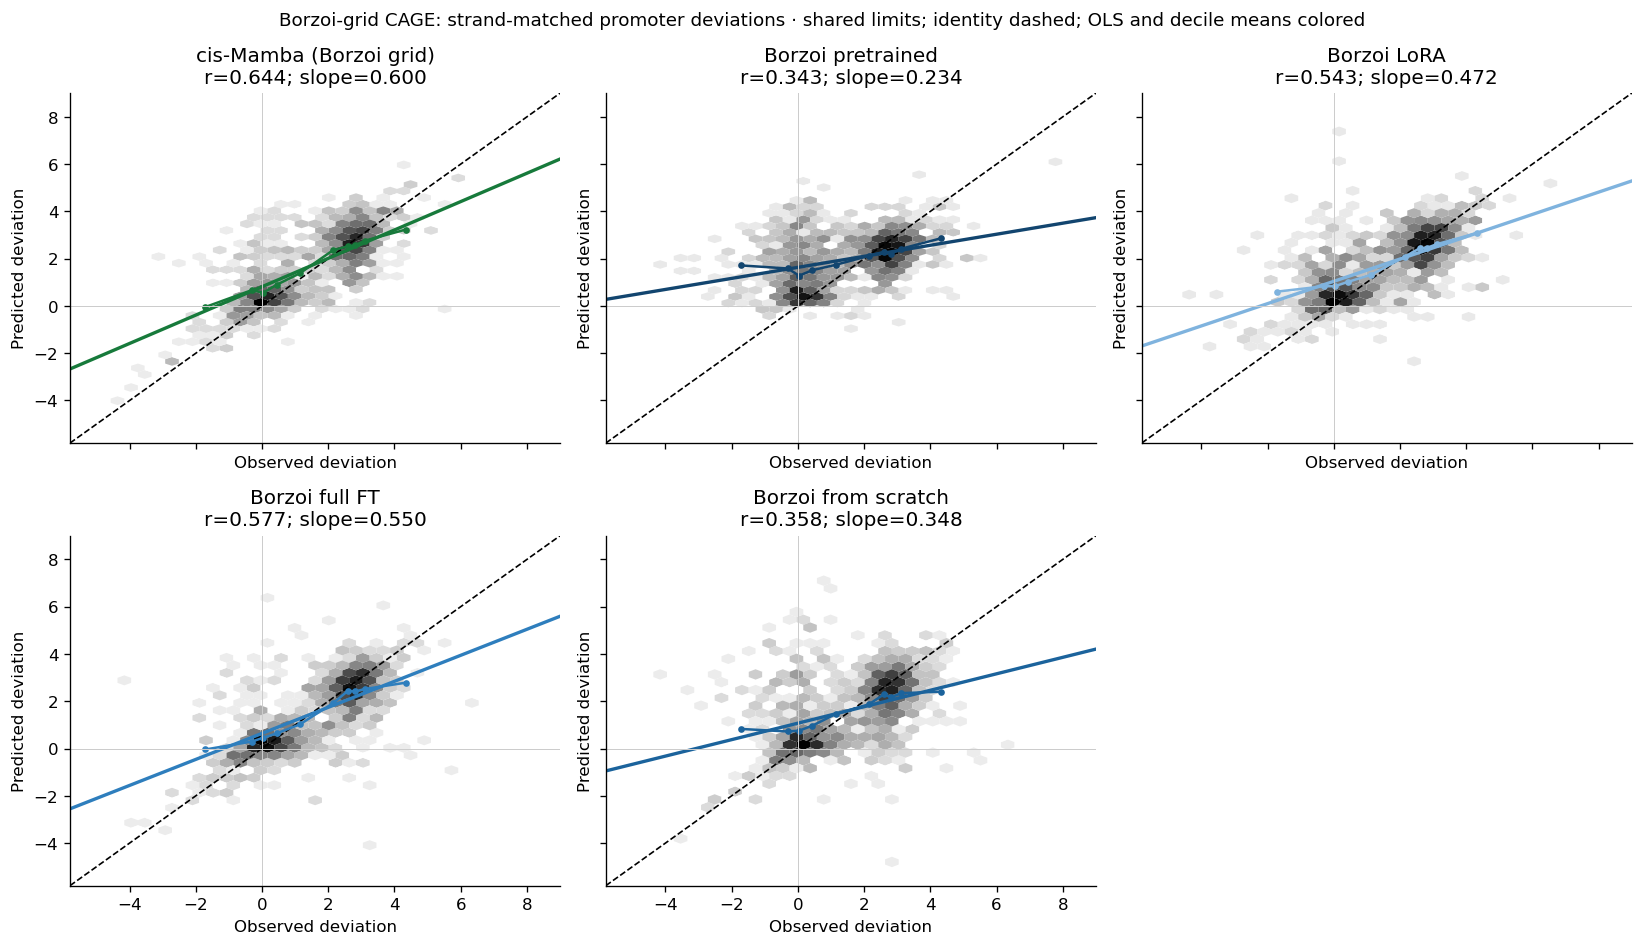

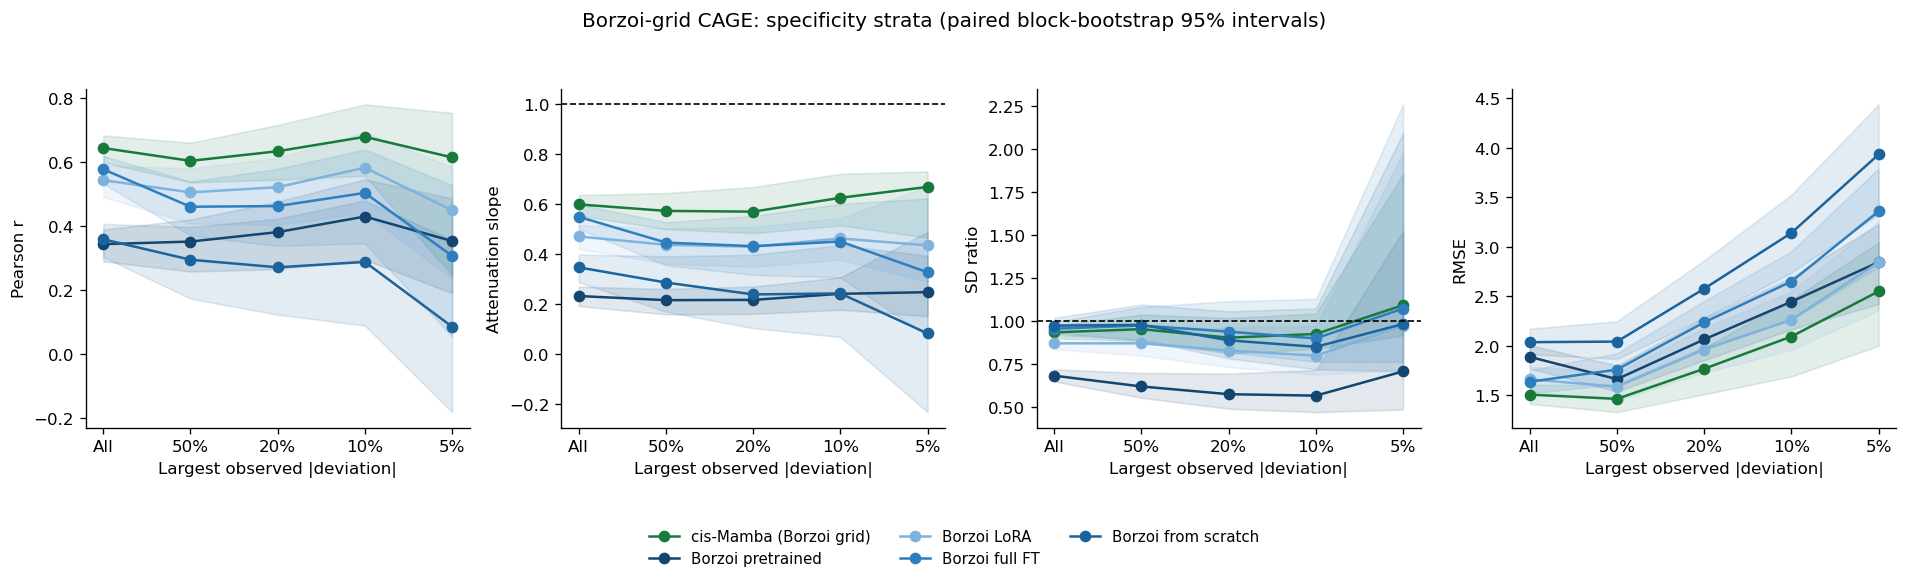

,subset,model,n_genes,expression_pearson,pearson,spearman,slope,sd_ratio,rmse,bias,skill_vs_mean
21,Top 10% |d|,cis-Mamba (Borzoi grid),194,0.6872,0.6785,0.3939,0.6265,0.9233,2.0946,-0.9165,0.7818
22,Top 10% |d|,Borzoi pretrained,194,0.4279,0.4295,0.2949,0.2424,0.5645,2.4465,-1.0255,0.7023
23,Top 10% |d|,Borzoi LoRA,194,0.5820,0.5822,0.3234,0.4639,0.7969,2.2634,-0.9688,0.7452
24,Top 10% |d|,Borzoi full FT,194,0.5566,0.5034,0.2320,0.4517,0.8972,2.6504,-1.2995,0.6506
25,Top 10% |d|,Borzoi from scratch,194,0.3877,0.2877,0.0347,0.2440,0.8481,3.1408,-1.6057,0.5093
35,Positive d,cis-Mamba (Borzoi grid),1460,0.9165,0.5613,0.5598,0.6172,1.0995,1.3401,-0.0765,0.7310
36,Positive d,Borzoi pretrained,1460,0.9065,0.3997,0.4089,0.3452,0.8636,1.3958,-0.0999,0.7081
37,Positive d,Borzoi LoRA,1460,0.9095,0.5139,0.5504,0.5457,1.0619,1.3876,-0.1486,0.7116
38,Positive d,Borzoi full FT,1460,0.9057,0.5142,0.5557,0.5895,1.1464,1.4858,-0.3495,0.6693
39,Positive d,Borzoi from scratch,1460,0.8556,0.3105,0.4054,0.3702,1.1922,1.7941,-0.3627,0.5177


,subset,left,right,metric,difference,lo,hi,valid_draws
0,All,cis-Mamba (Borzoi grid),Borzoi pretrained,pearson,0.3003,0.2439,0.3553,1000
3,All,cis-Mamba (Borzoi grid),Borzoi pretrained,rmse,-0.3814,-0.4810,-0.2684,1000
18,Top 10% |d|,cis-Mamba (Borzoi grid),Borzoi pretrained,pearson,0.2491,0.1235,0.3832,1000
21,Top 10% |d|,cis-Mamba (Borzoi grid),Borzoi pretrained,rmse,-0.3519,-0.7105,-0.0559,1000
36,Negative d,cis-Mamba (Borzoi grid),Borzoi pretrained,pearson,0.3578,0.2553,0.4769,1000
39,Negative d,cis-Mamba (Borzoi grid),Borzoi pretrained,rmse,-0.9791,-1.1622,-0.8009,1000
54,All,Borzoi LoRA,Borzoi pretrained,pearson,0.1999,0.1741,0.2282,1000
57,All,Borzoi LoRA,Borzoi pretrained,rmse,-0.2268,-0.2839,-0.1765,1000
72,Top 10% |d|,Borzoi LoRA,Borzoi pretrained,pearson,0.1527,0.0863,0.2224,1000
75,Top 10% |d|,Borzoi LoRA,Borzoi pretrained,rmse,-0.1830,-0.3666,-0.0145,1000


In [12]:
B_FIG=scatter_grid(B_FRAME,B_MODELS,'Borzoi-grid CAGE: strand-matched promoter deviations')
B_FIG.savefig(EXT_OUT/'borzoi_all_scatter.png',dpi=160,bbox_inches='tight')
plt.show()
B_FIG=specificity(B_TABLE,'Borzoi-grid CAGE',B_MODELS)
B_FIG.savefig(EXT_OUT/'borzoi_specificity.png',dpi=160,bbox_inches='tight')
plt.show()
display(B_TABLE.loc[B_TABLE.model.isin(B_MODELS)&B_TABLE.subset.isin(['Top 10% |d|','Positive d','Negative d']),
                    ['subset']+EXT_COLUMNS].round(4))
display(B_PAIRS[B_PAIRS.subset.isin(['All','Top 10% |d|','Negative d'])&B_PAIRS.metric.isin(['rmse','pearson'])].round(4))

In [13]:
display(B_SENS[['model','pad','pseudocount','baseline','selection','n_genes','pearson','slope','sd_ratio','rmse']].round(4))
EXT_SUMMARY=[]
for assay,table,pairs,names in [('Enformer-grid CAGE',E_TABLE,E_PAIRS,E_MODELS),
                               ('Borzoi-grid CAGE',B_TABLE,B_PAIRS,B_MODELS)]:
    all_scores=table[(table.subset=='All')&table.model.isin(names)].sort_values('rmse')
    EXT_SUMMARY.append('**'+assay+' — all-gene results:**')
    for row in all_scores.itertuples():
        EXT_SUMMARY.append(f'{row.model}: deviation r={row.pearson:.3f}, slope={row.slope:.3f}, '
                           f'SD ratio={row.sd_ratio:.3f}, RMSE={row.rmse:.3f}.')
    cis='cis-Mamba' if assay=='Enformer-grid CAGE' else 'cis-Mamba (Borzoi grid)'
    strongest=all_scores[all_scores.model!=cis].iloc[0]['model']
    d=pairs[(pairs.subset=='All')&(pairs.left==cis)&(pairs.right==strongest)&(pairs.metric=='rmse')].iloc[0]
    EXT_SUMMARY.append(f'cis-Mamba minus the lowest-RMSE comparison arm ({strongest}): '
                       f'{d.difference:.3f} [95% CI {d.lo:.3f}, {d.hi:.3f}]. '
                       'This compares saved runs, with the modality and training caveats above.')
EXT_SUMMARY.append('**Specialization is not a universal ordering:** the single-cell cis-Mamba has higher '
                   'deviation correlation than the eight-cell model, while the eight-cell model has lower '
                   'point-estimate RMSE. Their paired RMSE interval includes zero. The no-pretraining arm '
                   'has worse RMSE than the original cis-Mamba. These results do not establish that fewer '
                   'cell types always improve expression prediction.')
B_ALL=B_TABLE[B_TABLE.subset=='All'].set_index('model')
B_PRE=B_ALL.loc['Borzoi pretrained']; B_FT=B_ALL.loc['Borzoi full FT']
EXT_SUMMARY.append(f'**Borzoi amplitude:** pretrained Borzoi has SD ratio {B_PRE.sd_ratio:.3f} '
                   f'[95% CI {B_PRE.sd_ratio_lo:.3f}, {B_PRE.sd_ratio_hi:.3f}], compared with '
                   f'{B_FT.sd_ratio:.3f} after full fine-tuning. This indicates compressed global '
                   'deviation spread for pretrained Borzoi on this native-scale readout, unlike the '
                   'original Enformer result. Fine-tuning substantially restores spread. It does not '
                   'isolate task count from other training or input differences.')
EXT_SUMMARY_TEXT='\n\n'.join(EXT_SUMMARY)
display(Markdown(EXT_SUMMARY_TEXT))

,model,pad,pseudocount,baseline,selection,n_genes,pearson,slope,sd_ratio,rmse
0,cis-Mamba (Borzoi grid),512,1.0,mean_log,all,1934,0.6436,0.6001,0.9324,1.5075
1,Borzoi pretrained,512,1.0,mean_log,all,1934,0.3433,0.2335,0.6804,1.8888
2,Borzoi LoRA,512,1.0,mean_log,all,1934,0.5431,0.4718,0.8686,1.6620
3,Borzoi full FT,512,1.0,mean_log,all,1934,0.5771,0.5504,0.9536,1.6375
4,Borzoi from scratch,512,1.0,mean_log,all,1934,0.3584,0.3482,0.9716,2.0375
5,cis-Mamba (Borzoi grid),256,1.0,mean_log,all,1934,0.6485,0.6076,0.9370,1.5350
6,Borzoi pretrained,256,1.0,mean_log,all,1934,0.3634,0.2547,0.7010,1.9260
7,Borzoi LoRA,256,1.0,mean_log,all,1934,0.5593,0.4895,0.8752,1.6810
8,Borzoi full FT,256,1.0,mean_log,all,1934,0.5910,0.5664,0.9584,1.6568
9,Borzoi from scratch,256,1.0,mean_log,all,1934,0.3693,0.3598,0.9742,2.0766


**Enformer-grid CAGE — all-gene results:**

cis-Mamba (8 CTs): deviation r=0.596, slope=0.554, SD ratio=0.930, RMSE=1.484.

cis-Mamba: deviation r=0.628, slope=0.643, SD ratio=1.024, RMSE=1.526.

cis-Mamba (no pretraining): deviation r=0.546, slope=0.580, SD ratio=1.062, RMSE=1.702.

Enformer: deviation r=0.463, slope=0.470, SD ratio=1.015, RMSE=1.801.

Enformer retrained (1 CT, 1536ch): deviation r=0.256, slope=0.271, SD ratio=1.056, RMSE=2.182.

Enformer retrained (16 CTs): deviation r=0.207, slope=0.207, SD ratio=0.996, RMSE=2.265.

Enformer retrained (42 CTs): deviation r=0.141, slope=0.141, SD ratio=1.003, RMSE=2.543.

Enformer retrained (1 CT, 768ch): deviation r=0.146, slope=0.156, SD ratio=1.073, RMSE=2.553.

cis-Mamba minus the lowest-RMSE comparison arm (cis-Mamba (8 CTs)): 0.042 [95% CI -0.016, 0.091]. This compares saved runs, with the modality and training caveats above.

**Borzoi-grid CAGE — all-gene results:**

cis-Mamba (Borzoi grid): deviation r=0.644, slope=0.600, SD ratio=0.932, RMSE=1.507.

Borzoi full FT: deviation r=0.577, slope=0.550, SD ratio=0.954, RMSE=1.638.

Borzoi LoRA: deviation r=0.543, slope=0.472, SD ratio=0.869, RMSE=1.662.

Borzoi pretrained: deviation r=0.343, slope=0.234, SD ratio=0.680, RMSE=1.889.

Borzoi from scratch: deviation r=0.358, slope=0.348, SD ratio=0.972, RMSE=2.038.

cis-Mamba minus the lowest-RMSE comparison arm (Borzoi full FT): -0.130 [95% CI -0.239, -0.023]. This compares saved runs, with the modality and training caveats above.

**Specialization is not a universal ordering:** the single-cell cis-Mamba has higher deviation correlation than the eight-cell model, while the eight-cell model has lower point-estimate RMSE. Their paired RMSE interval includes zero. The no-pretraining arm has worse RMSE than the original cis-Mamba. These results do not establish that fewer cell types always improve expression prediction.

**Borzoi amplitude:** pretrained Borzoi has SD ratio 0.680 [95% CI 0.647, 0.717], compared with 0.954 after full fine-tuning. This indicates compressed global deviation spread for pretrained Borzoi on this native-scale readout, unlike the original Enformer result. Fine-tuning substantially restores spread. It does not isolate task count from other training or input differences.

## C. Relationship to Kathail et al.: adaptation, not direct reproduction

I implemented **your proposed magnitude analysis** using standard statistical diagnostics and
the available outputs. The cell-specific-expression motivation is shared with Kathail and earlier
work. The present centering rule, promoter readout, amplitude/error metrics, and uncertainty procedure
are adaptations for this benchmark. Neither slope nor SD ratio is a newly invented metric.

I inspected [Methods §2.3](https://academic.oup.com/bioinformatics/article/42/9/btag626/8767764)
and the authors' [benchmark notebook, zero-based cells 10–11](https://github.com/ni-lab/basenji-phyloP/blob/conservation-input/basenji_phylop/scripts/basenji_phylop_benchmark.ipynb).

| Choice | Kathail implementation | This notebook |
|---|---|---|
| LogFC reference | Log2 of arithmetic mean signal plus 1; observed and predicted means computed separately | Mean of observed log2(signal+1), shared across models |
| Focal track | Included in the CAGE-panel mean | GM12878 excluded |
| Main specificity scores | Pearson/Spearman across TSSs per track; also across tracks per TSS | GM12878 correlation plus slope, SD ratio, bias, error, reference-baseline skill |
| Across-track preprocessing | Log2(signal+1), then independently z-score each track across TSSs in observations and predictions | No z-scoring; no matched full predicted-panel analysis |
| Readout | GENCODE v32 protein-coding TSS-overlapping bins; cached TSS-centered predictions | GENCODE v49 representative promoter; one annotation-selected transcript per gene; ±512-bp sum |
| Additional diagnostics here | — | Observed-tail and sign strata, paired genomic-block intervals, readout/reference sensitivities |

More explicitly, their logFC branch evaluates correlation between

\[
\log_2(s_{gc}+1)-\log_2\!\left(\frac1C\sum_k s_{gk}+1\right)
\quad\text{and}\quad
\log_2(\hat s_{gc}+1)-\log_2\!\left(\frac1C\sum_k\hat s_{gk}+1\right).
\]

Here the prediction instead subtracts the **observed** leave-GM12878-out mean of logs.
This allows single-output comparisons, but supplies a measured reference at evaluation time and
changes the quantity being tested. Our `log_mean` sensitivity changes the order of averaging and
logging only; it **does not** reproduce Kathail's separate predicted reference or track inclusion.

**Single-output limitation:** with only one predicted cell-type track, Kathail's own-panel
centering gives `log2(prediction + 1) - log2(prediction + 1) = 0` at every TSS.
Its correlation is therefore undefined, and an across-cell correlation cannot be computed.
A matched panel of specialist models predicting several cell types would make that comparison
possible. Having full panels for Enformer or Borzoi alone does not resolve this limitation
for the single-output cis-Mamba comparison.

Their logFC branch does not z-score. Z-scoring belongs to their separate across-track analysis.
The public notebook also sums prediction slice `[:, 1:3, :]`, while observed values are selected
from TSS-overlapping bins. Exact readout reproduction would require auditing the upstream HDF5
generation and cached TSS arrays; it should not be silently equated to our promoter sum or to the
three-bin attribution readout mentioned elsewhere in the paper.

Appropriate attribution: **a custom amplitude/error extension motivated by established
cell-specific expression benchmarks**, not “we reproduced Kathail” and not “we invented
mean-centered expression evaluation.” To add a directly comparable literature score, obtain matched
predicted panels and replicate their centering/readout separately. The original requirement to keep
amplitude information means their across-track standardization should not replace our amplitude analysis.

## Reproduction of the appended sections

Run `prepare_model8.py enformer_extra` and `prepare_model8.py borzoi` with the caduceus
environment (after `cage`), then execute these cells.